![logoduoc.png](https://duoc.modyocdn.com/uploads/31c5f434-c300-4e7b-a287-2a9eb18b08de/original/logo_duocuc.svg)



## Etapa 1: Comprensión del Negocio
### Descripción del Negocio

<img src="https://wildlife.faa.gov/assets/logoFAA.png" alt="logo FAA" width="80
"/>

Cliente: FAA (Federal Aviation Administration)


La autoridad de aviación civil busca utilizar la minería de datos para comprender en profundidad los incidentes de colisión entre aeronaves y fauna silvestre, con el objetivo de desarrollar e implementar estrategias más efectivas para reducir estos incidentes, mejorar la seguridad aérea y minimizar los costos asociados. El éxito del proyecto se medirá por la reducción real de los incidentes y sus consecuencias negativas.

La obtencion de los datos fueron tomados durante el año 1990 y 2023 y se encuentran en:
[FAA Wildlife Strike Database](https://wildlife.faa.gov/search)

## Objetivo del Negocio
El objetivo principal de este proyecto es mejorar la seguridad aérea y reducir los daños asociados a las colisiones entre aeronaves y fauna silvestre ("wildlife strikes" o "bird strikes") mediante el análisis y la modelización de datos históricos de incidentes. Los objetivos específicos son:

* Predecir la probabilidad de ocurrencia de incidentes: Utilizar modelos de clasificación para anticipar la probabilidad de que ocurra un "wildlife strike" en función de diversas variables (e.g., fase de vuelo, hora del día, condiciones climáticas, especie de ave). Esto permitirá identificar situaciones de alto riesgo y tomar medidas preventivas.
* Predecir la severidad del daño: Implementar modelos de regresión y/o clasificación para predecir la severidad del daño a la aeronave (e.g., nivel de daño, partes de la aeronave afectadas, costos de reparación) en función de las características del incidente. Esto ayudará a las aerolíneas y autoridades a prepararse para los posibles impactos de los incidentes.
* Identificar los factores de riesgo más influyentes: Determinar qué variables (o combinaciones de variables) tienen el mayor impacto en la probabilidad y severidad de los "wildlife strikes". Esto permitirá enfocar los esfuerzos de mitigación en las áreas más críticas.


## Variables a predecir

1. Variable predictoria de clasificación:
- Daño indicado al avión (INDICATED_DAMAGE):
Esta variable binaria indica si la aeronave sufrió algún tipo de daño como consecuencia del impacto con fauna silvestre. Poder predecir esta variable permite anticipar riesgos operacionales y de seguridad, además de justificar inversiones en mitigación de fauna en aeropuertos. Algunas variables relevantes para esta predicción podrían ser:

 - Fase del vuelo (PHASE_OF_FLT)
 - Altura de vuelo (HEIGHT)
 - Velocidad del avión (SPEED)
 - Tipo y masa del avión (AC_CLASS, AC_MASS)
 - Tamaño del ave (SIZE)
 - Número de aves golpeadas (BIRDS_STRUCK)
 - Tipo de motor (TYPE_ENG)

2. Variable predictora de Regresión:
+ hola


Dado que el diccionario de datos no calza con las variables identificamos a cual pertencia cada variable segun diccionario
- BIRDS_STRUCKS = NUM_STRUCK
- PHASE_OF_FLT = PHASE_OF_FLIGHT
- ENROUTE_STATE = ENROUTE

## Etapa 2: Comprensión de los Datos

#### Importación de las librerias

In [ ]:
!pip install missingno
!pip install imbalanced-learn
!pip install seaborn matplotlib
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
import pandas as pd
import plotly.graph_objects as go
import plotly.express as px
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import train_test_split

In [ ]:
from google.colab import files
uploaded = files.upload()
for fn in uploaded.keys():
    name=fn
df = pd.read_csv(name)

pd.set_option("display.max_rows", None)  # Show all rows
pd.set_option("display.max_columns", None) # Show all columns

Saving STRIKE_REPORTS.csv to STRIKE_REPORTS.csv


/tmp/ipython-input-2-762332394.py:5: DtypeWarning: Columns (18,21) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(name)


In [ ]:
df.head()

,INDEX_NR,INCIDENT_DATE,INCIDENT_MONTH,INCIDENT_YEAR,TIME,TIME_OF_DAY,AIRPORT_ID,AIRPORT,LATITUDE,LONGITUDE,RUNWAY,STATE,FAAREGION,LOCATION,ENROUTE_STATE,OPID,OPERATOR,REG,FLT,AIRCRAFT,AMA,AMO,EMA,EMO,AC_CLASS,AC_MASS,TYPE_ENG,NUM_ENGS,ENG_1_POS,ENG_2_POS,ENG_3_POS,ENG_4_POS,PHASE_OF_FLIGHT,HEIGHT,SPEED,DISTANCE,SKY,PRECIPITATION,AOS,COST_REPAIRS,COST_OTHER,COST_REPAIRS_INFL_ADJ,COST_OTHER_INFL_ADJ,INGESTED_OTHER,INDICATED_DAMAGE,DAMAGE_LEVEL,STR_RAD,DAM_RAD,STR_WINDSHLD,DAM_WINDSHLD,STR_NOSE,DAM_NOSE,STR_ENG1,DAM_ENG1,ING_ENG1,STR_ENG2,DAM_ENG2,ING_ENG2,STR_ENG3,DAM_ENG3,ING_ENG3,STR_ENG4,DAM_ENG4,ING_ENG4,STR_PROP,DAM_PROP,STR_WING_ROT,DAM_WING_ROT,STR_FUSE,DAM_FUSE,STR_LG,DAM_LG,STR_TAIL,DAM_TAIL,STR_LGHTS,DAM_LGHTS,STR_OTHER,DAM_OTHER,OTHER_SPECIFY,EFFECT,EFFECT_OTHER,BIRD_BAND_NUMBER,SPECIES_ID,SPECIES,REMARKS,REMAINS_COLLECTED,REMAINS_SENT,WARNED,NUM_SEEN,NUM_STRUCK,SIZE,NR_INJURIES,NR_FATALITIES,COMMENTS,REPORTED_NAME,REPORTED_TITLE,SOURCE,PERSON,LUPDATE,TRANSFER
0,608242,6/22/1996,6,1996,NaN,NaN,KSMF,SACRAMENTO INTL,38.69542,-121.59077,NaN,CA,AWP,NaN,NaN,UAL,UNITED AIRLINES,NaN,1768.0,B-737-300,148,24,10.0,1.0,A,4.0,D,2.0,1.0,1.0,NaN,NaN,Take-off Run,0.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,False,NaN,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,NaN,NaN,NaN,NaN,UNKBM,Unknown bird - medium,BLOOD ON L FWD NOSE AREA SEEN BY CREW AFTER LDG.,False,False,Unknown,NaN,1,Medium,NaN,NaN,/Legacy Record=100001/,REDACTED,REDACTED,Air Transport Report,Air Transport Operations,12/20/2007,False
1,608243,6/26/1996,6,1996,NaN,NaN,KDEN,DENVER INTL AIRPORT,39.85841,-104.66700,NaN,CO,ANM,NaN,NaN,UAL,UNITED AIRLINES,NaN,1845.0,B-737-300,148,24,10.0,1.0,A,4.0,D,2.0,1.0,1.0,NaN,NaN,Take-off Run,0.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,False,NaN,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,NaN,NaN,NaN,NaN,UNKBM,Unknown bird - medium,CREW SUSPECTED BIRDSTRIKE ON T/O. LOOKED LIKE ...,False,False,Unknown,NaN,1,Medium,NaN,NaN,/Legacy Record=100002/,REDACTED,REDACTED,Air Transport Report,Air Transport Operations,12/20/2007,False
2,608244,7/1/1996,7,1996,NaN,NaN,KOMA,EPPLEY AIRFIELD,41.30252,-95.89417,NaN,NE,ACE,NaN,NaN,UAL,UNITED AIRLINES,NaN,306.0,B-757-200,148,26,34.0,40.0,A,4.0,D,2.0,1.0,1.0,NaN,NaN,Take-off Run,0.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,False,N,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,NaN,NaN,NaN,NaN,UNKBM,Unknown bird - medium,BIRDSTRIKE AT ROTATION. INSPN. NO DMG.,False,False,Unknown,NaN,1,Medium,NaN,NaN,/Legacy Record=100003/,REDACTED,REDACTED,Air Transport Report,Air Transport Operations,12/20/2007,False
3,608245,7/1/1996,7,1996,NaN,NaN,KIAD,WASHINGTON DULLES INTL ARPT,38.94453,-77.45581,NaN,DC,AEA,NaN,NaN,UAL,UNITED AIRLINES,NaN,510.0,A-320,04A,03,23.0,1.0,A,4.0,D,2.0,1.0,1.0,NaN,NaN,Approach,1000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,False,N,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,NaN,NaN,NaN,NaN,UNKBM,Unknown bird - medium,"ON FINAL APCH, STRIKE UNDER THE NOSE OF THE CO...",False,False,Unknown,NaN,1,Medium,NaN,NaN,/Legacy Record=100004/,REDACTED,REDACTED,Air Transport Report,Air Transport Operations,12/20/2007,False
4,608246,7/1/1996,7,1996,NaN,NaN,KLGA,LA GUARDIA ARPT,40.77724,-73.87261,NaN,NY,AEA,NaN,NaN,UAL,UNITED AIRLINES,NaN,677.0,A-320,04A,03,23.0,1.0,A,4.0,D,2.0,1.0,1.0,NaN,NaN,Climb,5000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,True,M,False,False,False,False,False,False,True,False,False,False,False,False,False,F

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 288810 entries, 0 to 288809
Data columns (total 100 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   INDEX_NR               288810 non-null  int64  
 1   INCIDENT_DATE          288810 non-null  object 
 2   INCIDENT_MONTH         288810 non-null  int64  
 3   INCIDENT_YEAR          288810 non-null  int64  
 4   TIME                   163633 non-null  object 
 5   TIME_OF_DAY            166394 non-null  object 
 6   AIRPORT_ID             288804 non-null  object 
 7   AIRPORT                288810 non-null  object 
 8   LATITUDE               253309 non-null  float64
 9   LONGITUDE              253308 non-null  float64
 10  RUNWAY                 218852 non-null  object 
 11  STATE                  253309 non-null  object 
 12  FAAREGION              253309 non-null  object 
 13  LOCATION               33939 non-null   object 
 14  ENROUTE_STATE          5037 non-nul

In [ ]:
df.describe()

,INDEX_NR,INCIDENT_MONTH,INCIDENT_YEAR,LATITUDE,LONGITUDE,EMA,EMO,AC_MASS,NUM_ENGS,ENG_1_POS,ENG_2_POS,ENG_3_POS,ENG_4_POS,HEIGHT,SPEED,DISTANCE,AOS,BIRD_BAND_NUMBER,NR_INJURIES,NR_FATALITIES
count,2.888100e+05,288810.000000,288810.000000,2.533090e+05,253308.000000,192151.000000,186756.000000,206490.000000,206259.000000,205481.000000,191612.000000,13080.000000,3290.000000,148807.000000,94237.000000,188234.000000,14196.000000,3.900000e+02,276.000000,24.000000
mean,8.736693e+05,7.175974,2011.697798,2.012754e+02,-90.880247,19.755812,8.522377,3.538312,2.013929,2.814956,2.667536,2.900306,2.043161,865.960358,142.585057,0.814466,91.454416,8.811022e+07,1.293478,2.041667
std,2.526448e+05,2.765082,8.432311,8.177522e+04,327.243918,10.724278,12.866405,0.867312,0.420133,2.113806,1.981032,1.950649,1.435114,1843.098801,46.650050,3.547950,661.074472,9.110186e+07,0.756134,1.654484
min,6.082420e+05,1.000000,1990.000000,-3.767333e+01,-177.381000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,1.000000,1.000000
25%,6.893202e+05,5.000000,2006.000000,3.298764e+01,-98.469780,10.000000,1.000000,3.000000,2.000000,1.000000,1.000000,1.000000,1.000000,0.000000,120.000000,0.000000,1.000000,0.000000e+00,1.000000,1.000000
50%,7.646935e+05,7.000000,2014.000000,3.880581e+01,-87.904460,22.000000,4.000000,4.000000,2.000000,1.000000,1.000000,1.000000,1.000000,50.000000,140.000000,0.000000,3.000000,7.897730e+07,1.000000,1.500000
75%,1.064714e+06,9.000000,2019.000000,4.085010e+01,-80.417940,31.000000,10.000000,4.000000,2.000000,5.000000,5.000000,5.000000,4.000000,900.000000,160.000000,0.000000,24.000000,1.893343e+08,1.000000,2.000000
max,1.472259e+06,12.000000,2023.000000,4.115443e+07,164140.000000,92.000000,2301.000000,5.000000,4.000000,7.000000,7.000000,6.000000,5.000000,31300.000000,1250.000000,99.000000,62848.000000,2.821218e+08,7.000000,8.000000


El conjunto de datos contiene más de 280.000 registros y múltiples variables relacionadas con incidentes entre aeronaves y fauna silvestre. Esta dimensión es adecuada para realizar análisis estadísticos y modelado predictivo.
Sin embargo, se identificaron diferencias notables en la cantidad de datos disponibles por variable. Algunas variables como HEIGHT (altura de vuelo) y SPEED (velocidad) presentan una alta proporción de valores nulos, lo que podría afectar su uso en modelos predictivos si no se realiza un tratamiento adecuado.

In [ ]:
df['INCIDENT_DATE'] = pd.to_datetime(df['INCIDENT_DATE'], errors='coerce')
print(f"Fecha mas antigua: {df['INCIDENT_DATE'].min()}")
print(f"Fecha mas reciente: {df['INCIDENT_DATE'].max()}")

Fecha mas antigua: 1990-01-02 00:00:00
Fecha mas reciente: 2023-11-14 00:00:00


### Analisis de valores nulos

In [ ]:
# Revisar la cantidad de nulos por columna
null_summary = df.isnull().sum().sort_values(ascending=False)
null_summary_percentage = (null_summary / len(df)) * 100

# Combinar cantidad y porcentaje de nulos en un solo DataFrame
null_report = pd.DataFrame({
    'missing_values': null_summary,
    'percent_missing': null_summary_percentage
})
null_report.head(51)  # Mostrar las 51 columnas con más nulos


,missing_values,percent_missing
NR_FATALITIES,288786,99.991690
NR_INJURIES,288534,99.904435
BIRD_BAND_NUMBER,288420,99.864963
EFFECT_OTHER,286589,99.230982
ENG_4_POS,285520,98.860843
COST_OTHER_INFL_ADJ,284050,98.351858
COST_OTHER,284050,98.351858
ENROUTE_STATE,283773,98.255947
COST_REPAIRS_INFL_ADJ,283770,98.254908
COST_REPAIRS,283770,98.254908


<Axes: >

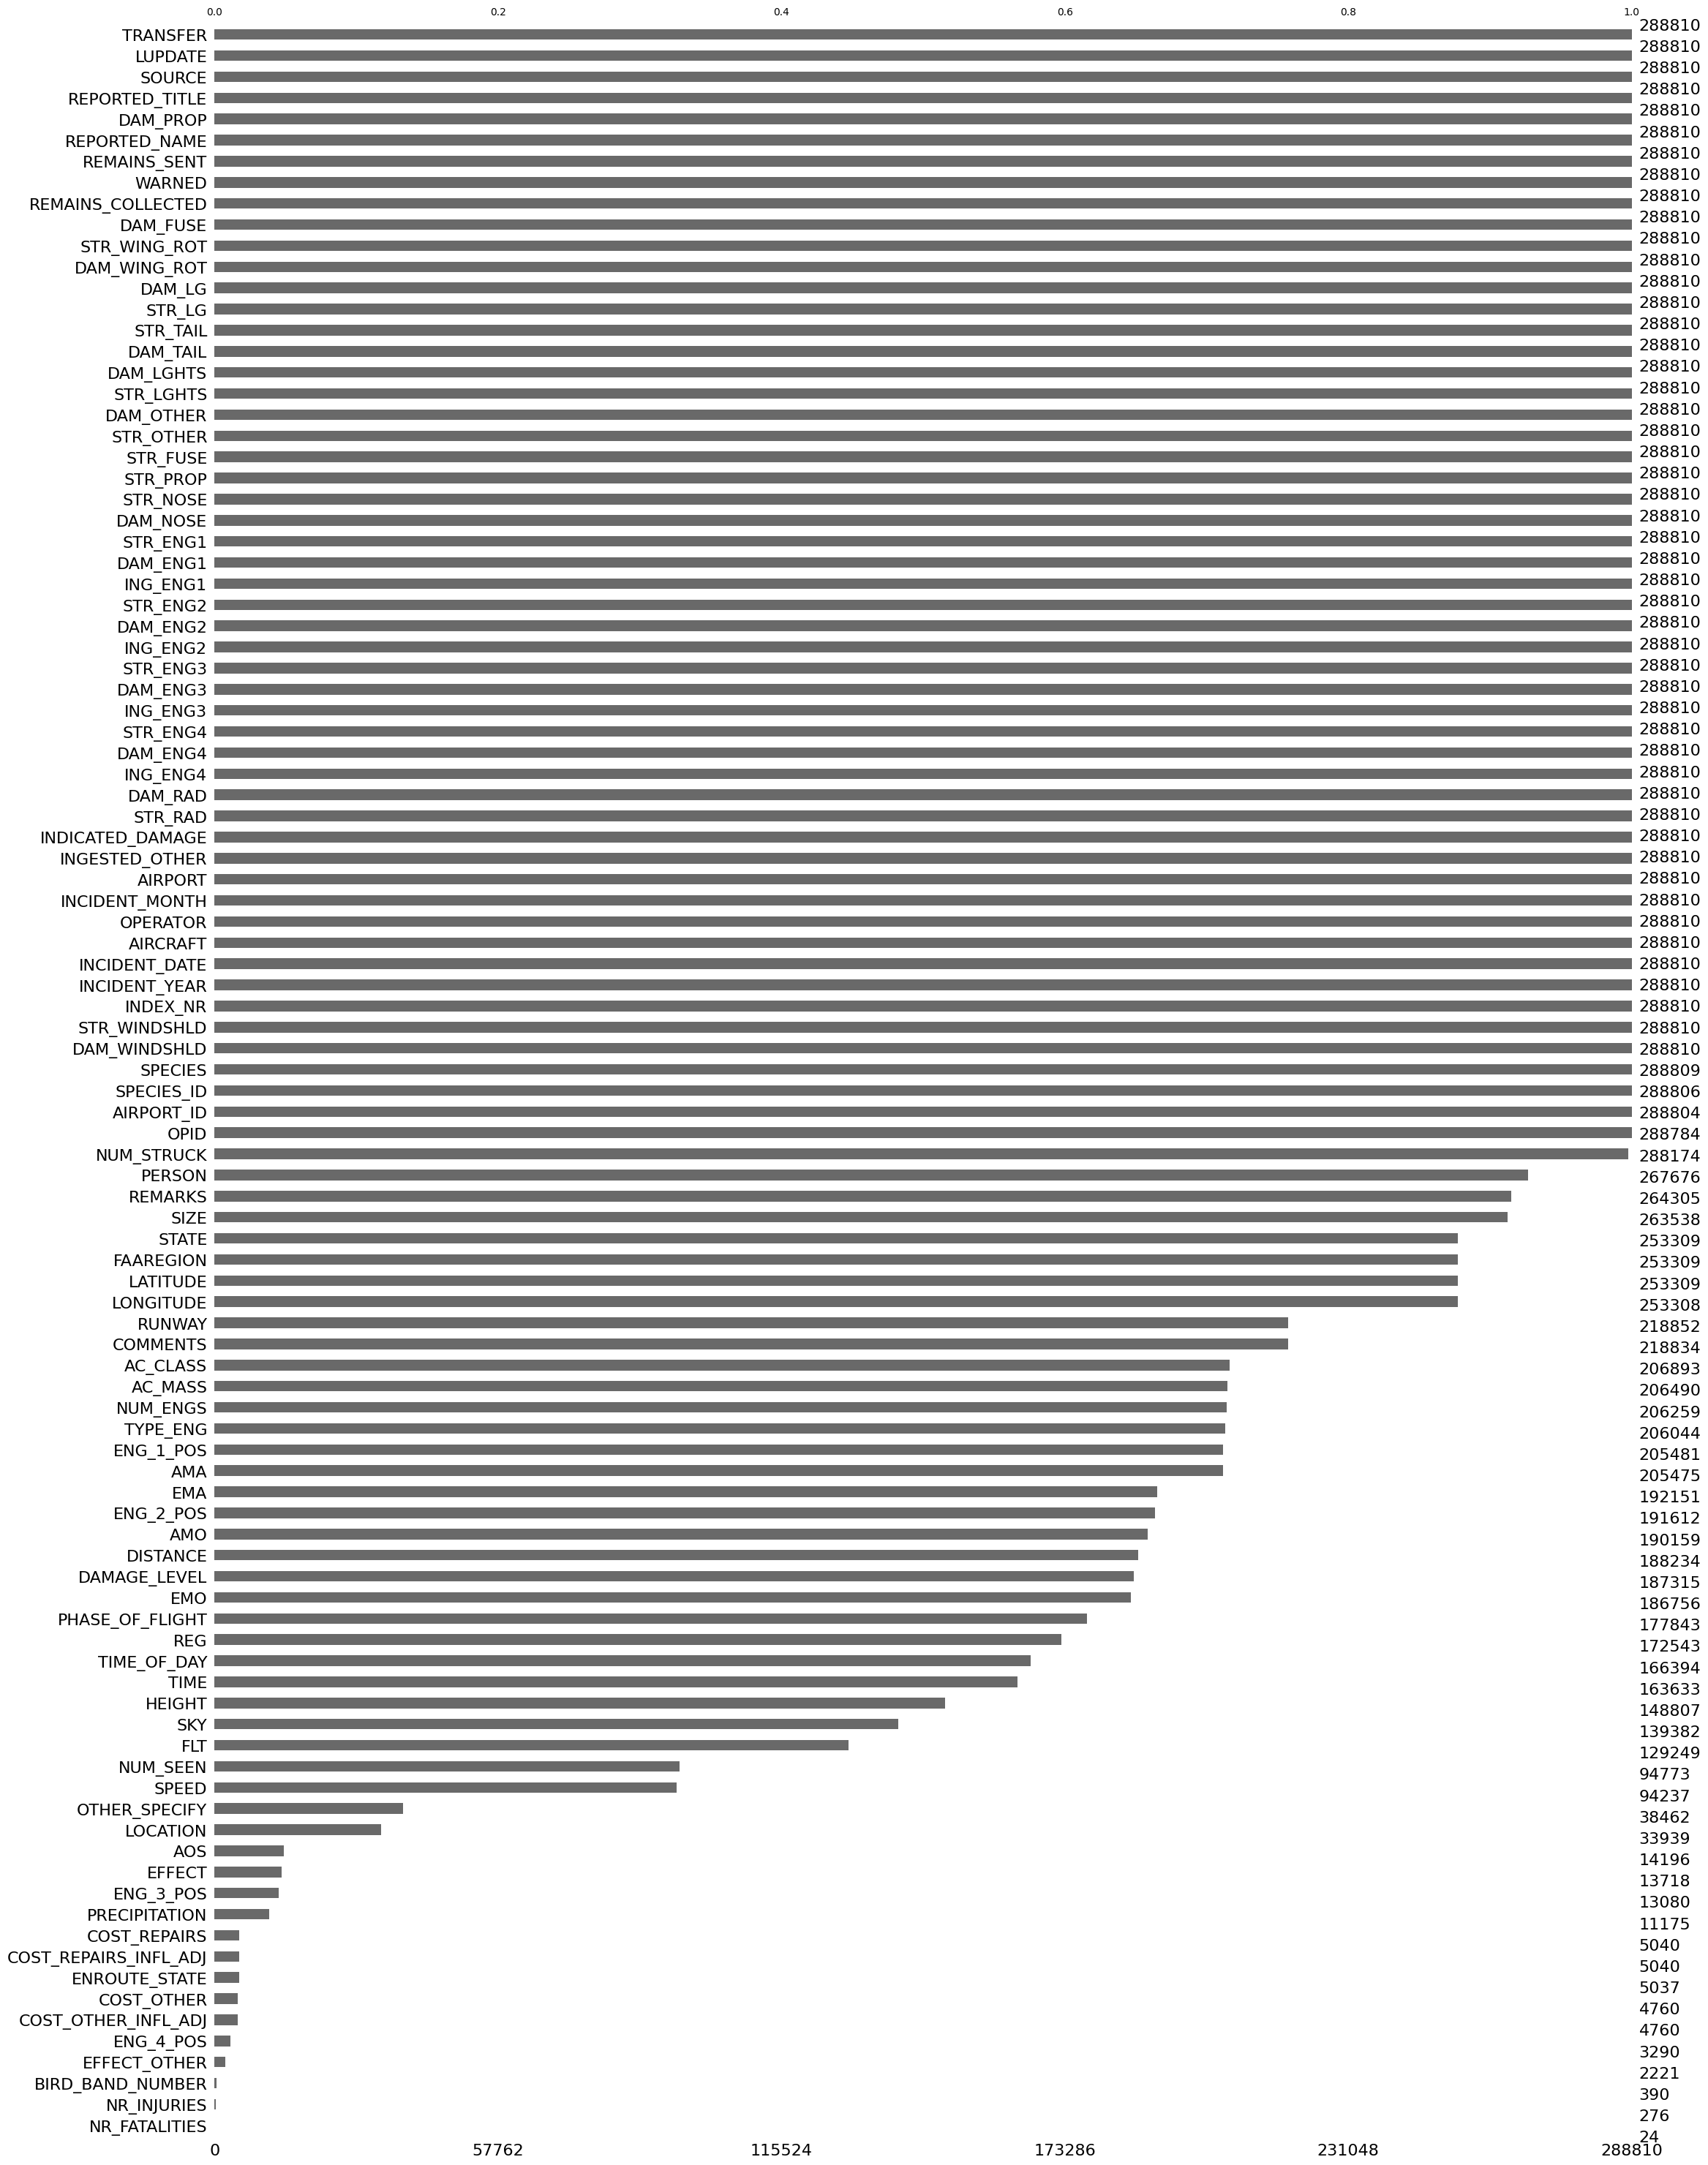

In [ ]:
msno.bar(df, sort='ascending')

<Axes: >

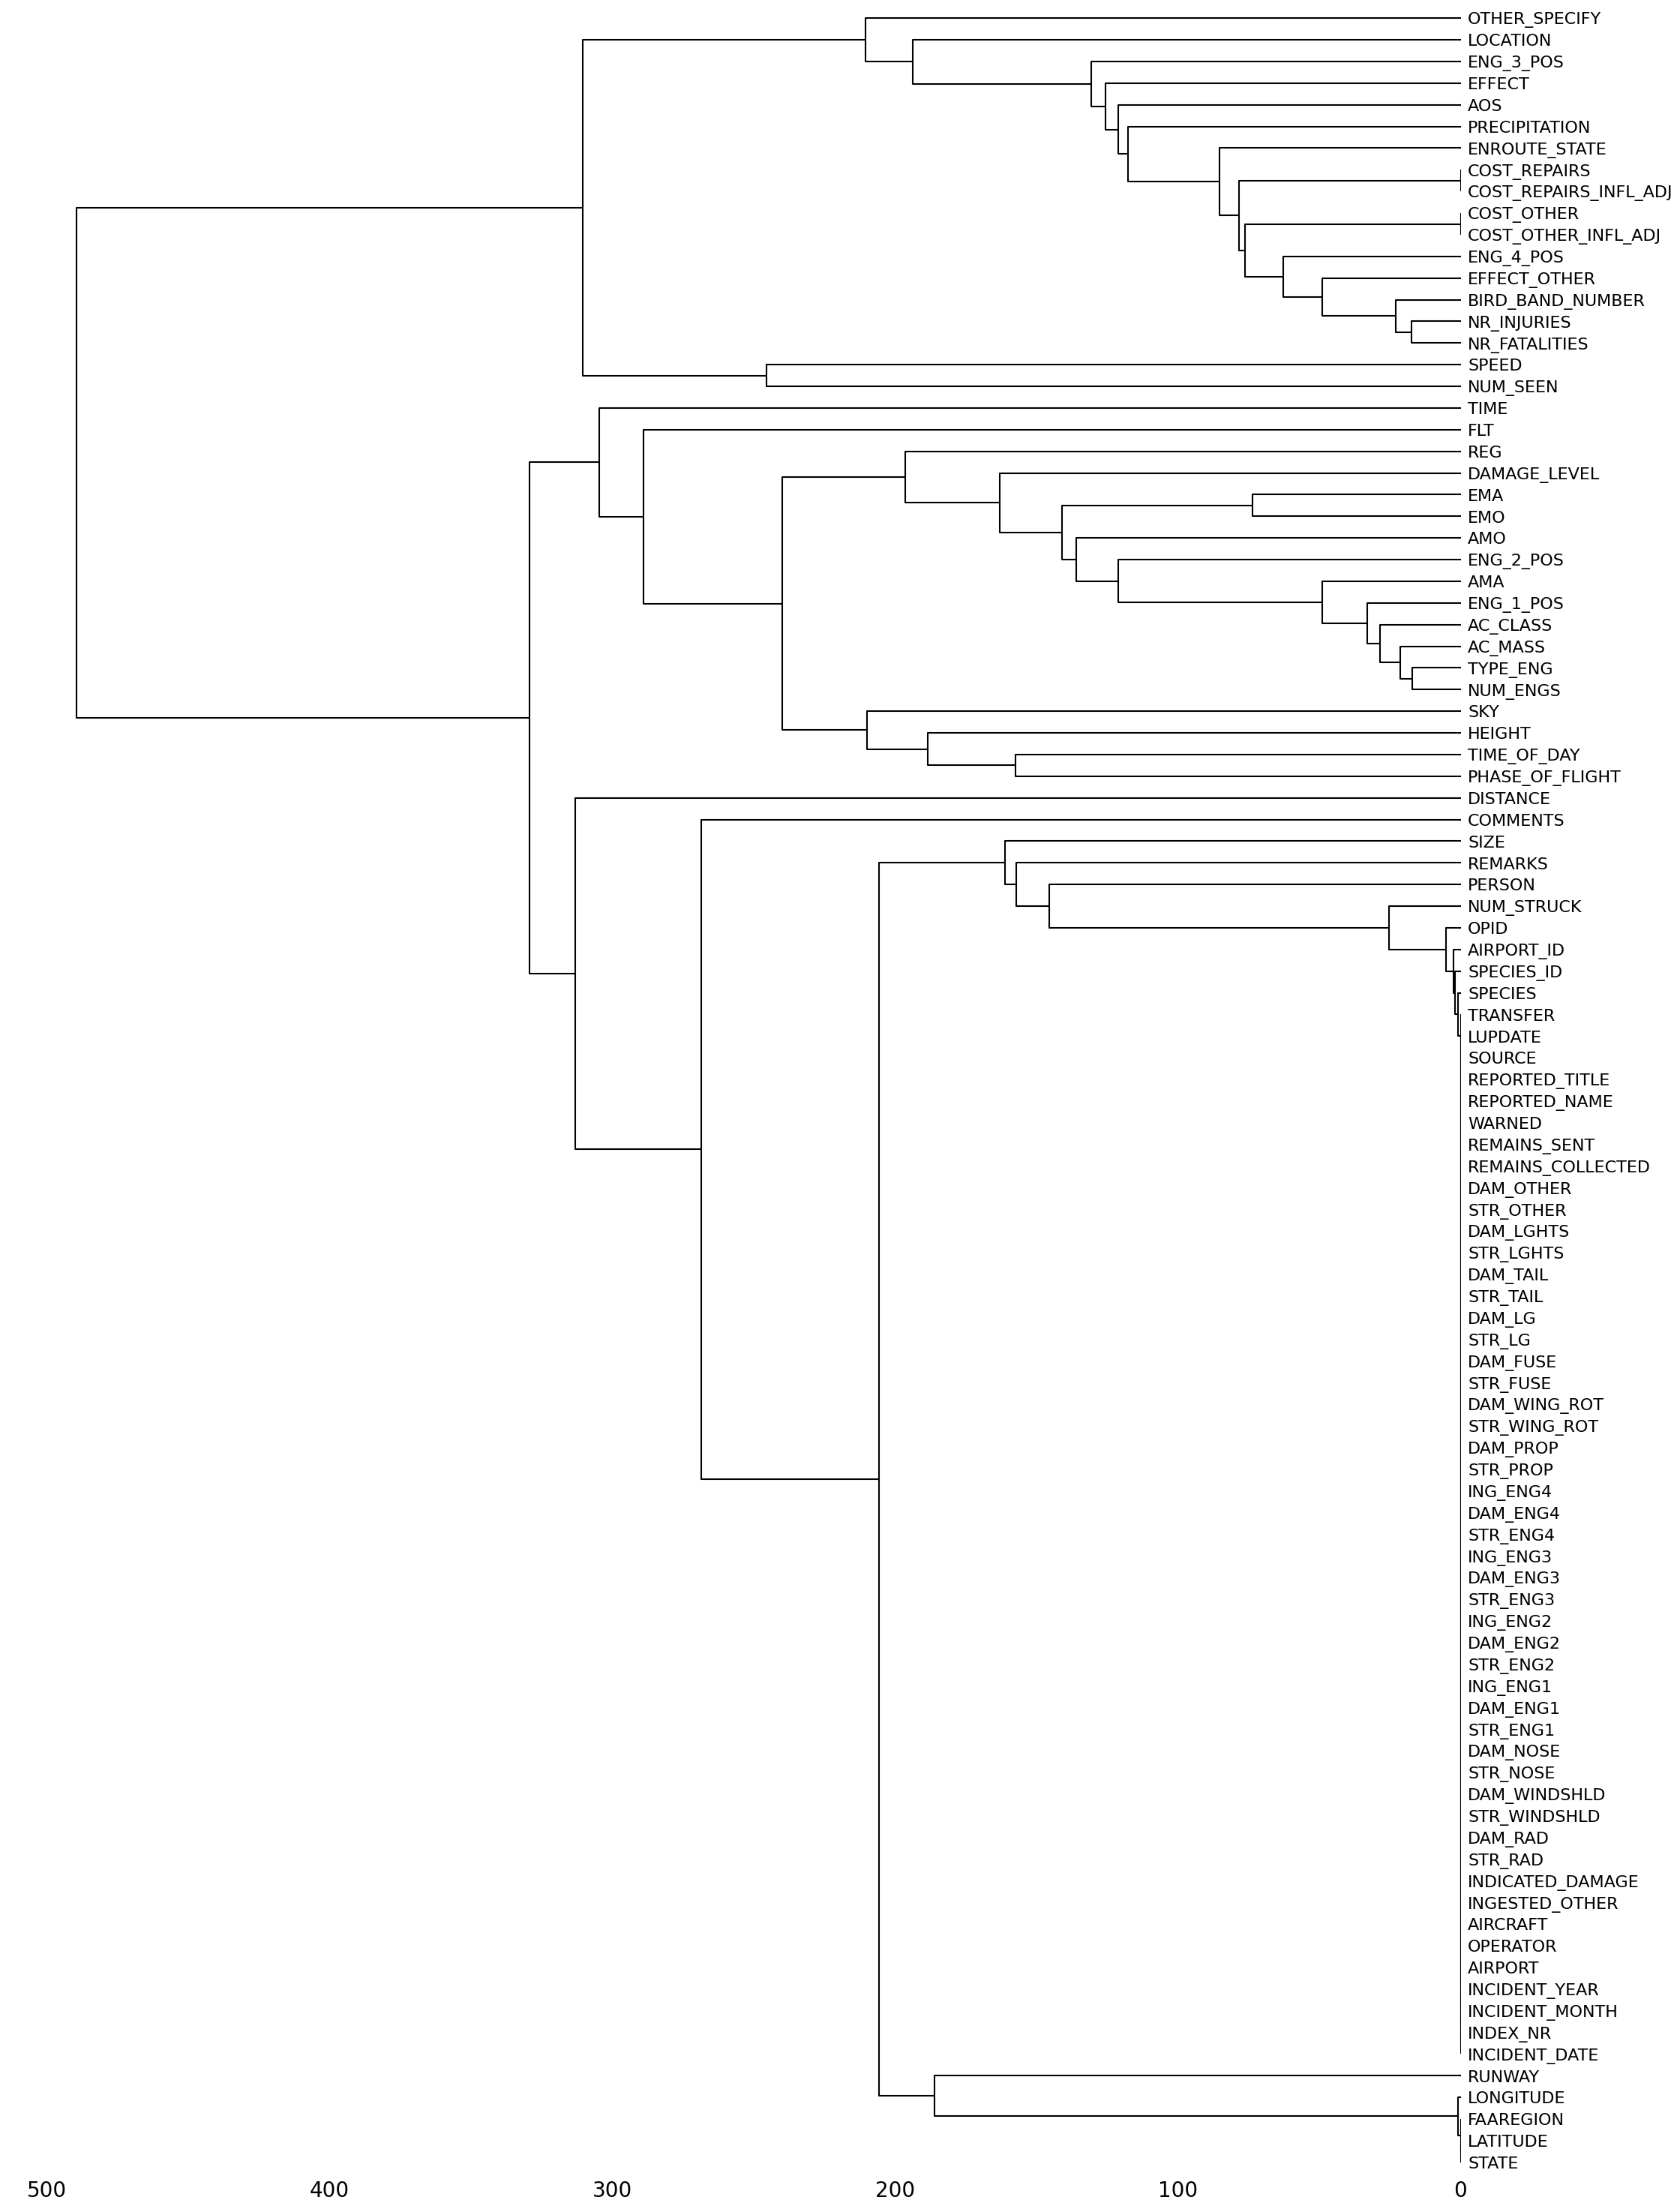

In [ ]:
msno.dendrogram(df)

`LONGITUDE, LATITUDE, STATE `: Estas tres están extremadamente agrupadas a una distancia muy baja. Esto es una indicación muy fuerte de que si una de ellas falta, las otras también son altamente propensas a faltar. Esto tiene sentido geográficamente.

`INCIDENT_YEAR, INCIDENT_MONTH, INCIDENT_DATE`: Estas también están estrechamente agrupadas. Si tienes la información de la fecha de un incidente, es probable que tengas el año y el mes. OPERATOR está justo por encima de este grupo, lo que sugiere una conexión también.


Un Gran Cluster Superior: Parece haber un gran cluster de columnas que se ramifican juntas en la parte superior, que incluye variables como `OTHER_SPECIFY, DMG_1_POS, ENG_1_POS, AIRCRAFT, ADS, PRECIPITATION, ENROUTE_STATE, EQUIPMENT, COST_REPAIRS_INFL_ADJ, COST_OTHER, COST_TOTAL_INFL_ADJ, ENG_2_POS, ENG_3_POS, BIRD_BAND_NUMBER, FLT_DATE, NR_FATALITIES, NR_INJ, NUM_SEEN, ALT, GS, HT, DAMAGE_LEVEL, PHASE, RMK, AMAS, DMG_2_POS, DMG_3_POS, AIRCRAFT_CLASS, AC_CLASS, REP_DATE, TYPE_ENG, DAMAGE_ENG3, SKY, MILES, HEIGHT, TIME_OF_DAY, STANDOFF_FLIGHT, DISTANCE, REMARKS, SIZE, PERSON, AIRCRAFT_TRUCK`.
Esto sugiere que muchas de estas variables tienen patrones de valores faltantes relacionados, aunque quizás no tan idénticos como los clusters de "fecha" o "ubicación". Podría indicar que estos campos a menudo se registran juntos o no se registran en ciertos tipos de incidentes.
La presencia de DMG_2_POS, DMG_3_POS, DAMAGE_ENG3, etc., dentro de este cluster, junto con DAMAGE_LEVEL, es lógica, ya que la información sobre el daño suele estar interconectada.
`STR_RAD, STR_RAD_DAMAGE, INGESTED_OTHER`: Estas columnas están agrupadas un poco más abajo, lo que sugiere que su información sobre el impacto o ingestión de radar también está correlacionada.

`Variables de STR_ENG y DMG_ENG (en el medio)`: Hay un gran bloque de variables relacionadas con STR_ENG1, STR_ENG2, STR_ENG3, STR_ENG4, STR_ENG5, DMG_ENG1, DMG_ENG2, etc. Estas están muy agrupadas. Esto indica fuertemente que si se registra información para un motor específico, es probable que se registre información similar para otros motores o que falten en conjunto. Esto es de esperar en datos relacionados con motores de aeronaves.

### Analisis de variables

In [ ]:
# Contar los valores únicos en la columna 'INDICATED_DAMAGE'
damage_counts = df['INDICATED_DAMAGE'].value_counts().reset_index()
damage_counts.columns = ['INDICATED_DAMAGE', 'COUNT']

# Crear el gráfico de pastel
fig = px.pie(damage_counts, values='COUNT', names='INDICATED_DAMAGE', title='Distribución de Daños Indicados')
fig.show()

Vemos que la variable INDICATED_DAMAGE esta bastante desbalanceada asi que tendremos que, luego de procesar en la fase 3 las variables, hacer un smote para balancear las clases y asi evitar el sesgo en los modelos que vayamos a implementar

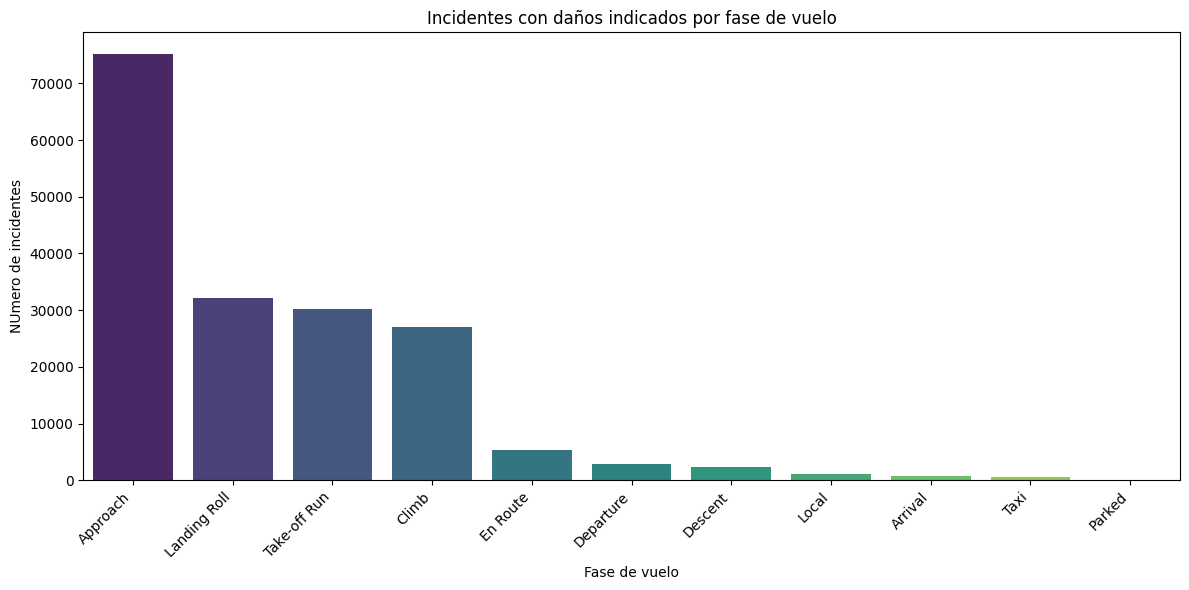

In [ ]:

# Filter incidents with indicated damage
df_damaged = df[df['INDICATED_DAMAGE'].notna()]

damage_by_phase = df_damaged['PHASE_OF_FLIGHT'].value_counts().reset_index()
damage_by_phase.columns = ['PHASE_OF_FLIGHT', 'INCIDENT_COUNT']

# bar plot
plt.figure(figsize=(12, 6))
sns.barplot(x='PHASE_OF_FLIGHT', y='INCIDENT_COUNT', data=damage_by_phase, palette='viridis')
plt.title('Incidentes con daños indicados por fase de vuelo')
plt.xlabel('Fase de vuelo')
plt.ylabel('NUmero de incidentes')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Vemos que hay 4 fases del vuelo que mas incidentes tienen que serian la fase de aterrizaje, seguido de la fase de frenado de aterrizaje, es decir, la distancia que el avión recorre sobre la pista desde el punto de contacto inicial (cuando las ruedas tocan la pista) hasta que se detiene por completo, le sigue la fase de despegue y finalmente climb que significa ascenso, o la maniobra de subir en altura con una aeronave

<Figure size 1200x600 with 0 Axes>

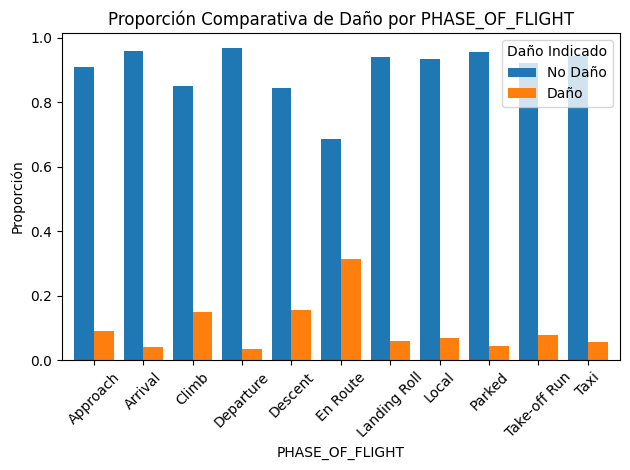

<Figure size 1200x600 with 0 Axes>

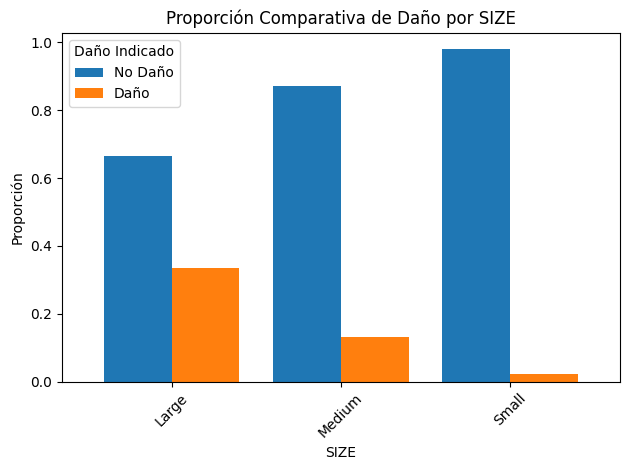

<Figure size 1200x600 with 0 Axes>

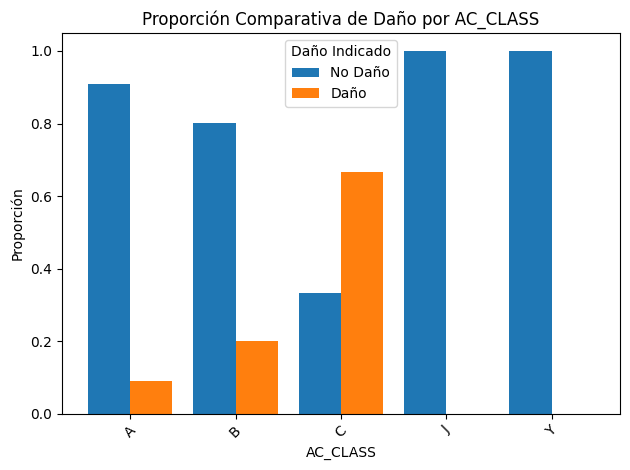

<Figure size 1200x600 with 0 Axes>

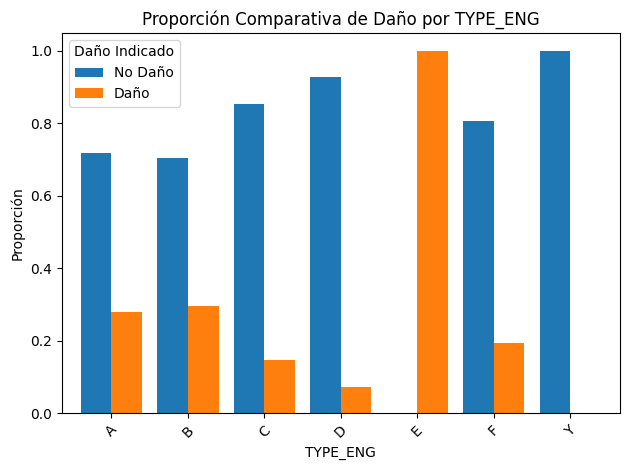

In [ ]:
# Lista de columnas categóricas para analizar
categorical_cols = ['PHASE_OF_FLIGHT', 'SIZE', 'AC_CLASS', 'TYPE_ENG']

for col in categorical_cols:
    if col in df.columns and 'INDICATED_DAMAGE' in df.columns:
        plt.figure(figsize=(12, 6))
        # Crear la tabla de contingencia con proporciones por categoría
        crosstab_df = pd.crosstab(df[col], df['INDICATED_DAMAGE'], normalize='index')
        # Renombrar columnas si es necesario para mejor legibilidad
        crosstab_df.columns = ['No Daño', 'Daño'] if len(crosstab_df.columns) == 2 else crosstab_df.columns
        # Reorganizar el DataFrame para mejor orden
        crosstab_df = crosstab_df[['No Daño', 'Daño']] if 'No Daño' in crosstab_df.columns else crosstab_df
        # Plot de barras lado a lado (comparativo)
        ax = crosstab_df.plot.bar(rot=45, width=0.8)
        plt.title(f'Proporción Comparativa de Daño por {col}')
        plt.xlabel(col)
        plt.ylabel('Proporción')
        plt.legend(title='Daño Indicado')
        plt.tight_layout()
        plt.show()


* Fase del Vuelo: La fase "En Route" (vuelo de crucero) es la que presenta la mayor proporción de daño, seguida por las fases de despegue y aproximación. Esto sugiere que los incidentes que ocurren durante el vuelo estable, aunque menos frecuentes, son más propensos a resultar en daño a la aeronave.

* Tamaño de la Aeronave (SIZE): Existe una clara correlación positiva entre el tamaño de la aeronave y la proporción de daño. Las aeronaves grandes son significativamente más propensas a sufrir daño en un incidente que las pequeñas. Esto podría deberse a la complejidad, el tipo de operaciones que realizan o la magnitud de los incidentes que afectan a aeronaves más grandes.
* Clase de Aeronave (AC_CLASS): Ees evidente que la Clase "C" es un factor de riesgo importante para el daño, mientras que las clases "J" y "Y" son muy seguras en este aspecto.
* Tipo de Motor (TYPE_ENG): El tipo de motor "E" es un fuerte predictor de daño, con una proporción casi del 100%. Otros tipos como "F" también tienen alta proporción de daño, mientras que "D" y "Y" tienen muy baja. Esto podría indicar problemas inherentes a ciertos diseños de motor, o que esos motores están instalados en aeronaves que operan en condiciones más riesgosas.

In [ ]:
# Seleccionar columnas por tipo de dato
categoricas_cols = df.select_dtypes(include=['object', 'bool']).columns.tolist()
numericas_cols = df.select_dtypes(include=['float64', 'int64']).columns.tolist()

# Excluir identificadores y columnas que no son variables continuas
excluir = ['INDEX_NR', 'INCIDENT_MONTH', 'INCIDENT_YEAR']
numericas_lineales = [col for col in numericas_cols if col not in excluir]
df_categoricas = df[categoricas_cols]
df_numericas = df[numericas_lineales]

### Analisis de datos atipicos


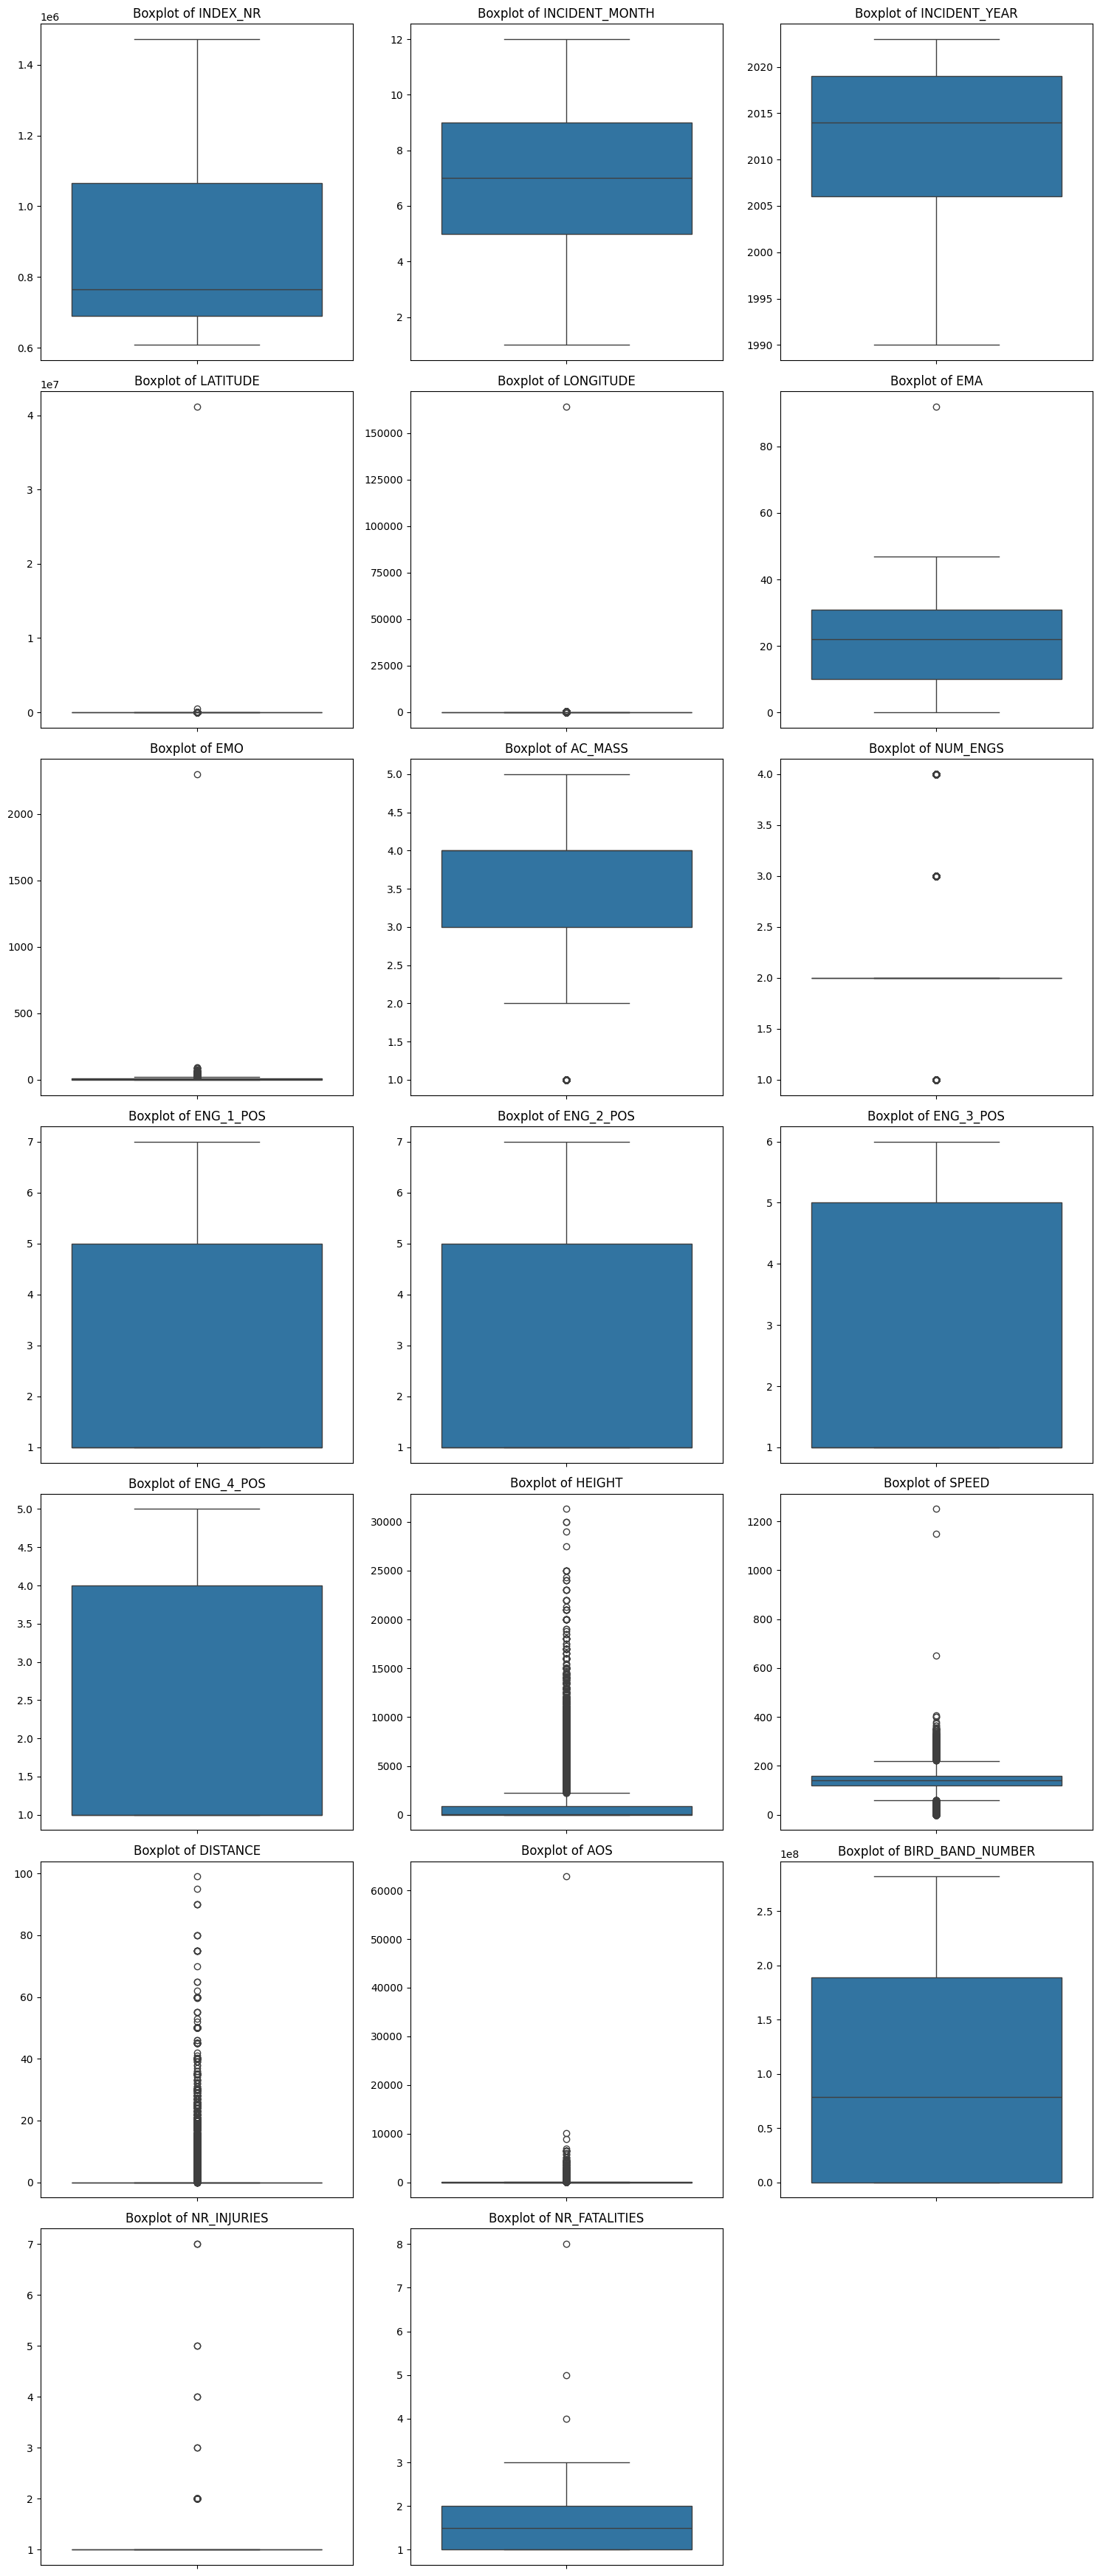

In [ ]:
df_numericas = df.select_dtypes(include=np.number)

# Calculate the number of rows and columns for the subplots dynamically
n_cols = len(df_numericas.columns)
n_rows = (n_cols + 2) // 3  # Simple way to calculate rows needed for 3 columns per row

plt.figure(figsize=(15, n_rows * 5)) # Adjust figure height based on number of rows

for i, col in enumerate(df_numericas.columns):
    # Use the calculated number of rows and columns for subplot grid
    plt.subplot(n_rows, 3, i + 1)
    sns.boxplot(y=df_numericas[col])
    plt.title(f'Boxplot of {col}')
    plt.ylabel('')
plt.tight_layout()
plt.show()

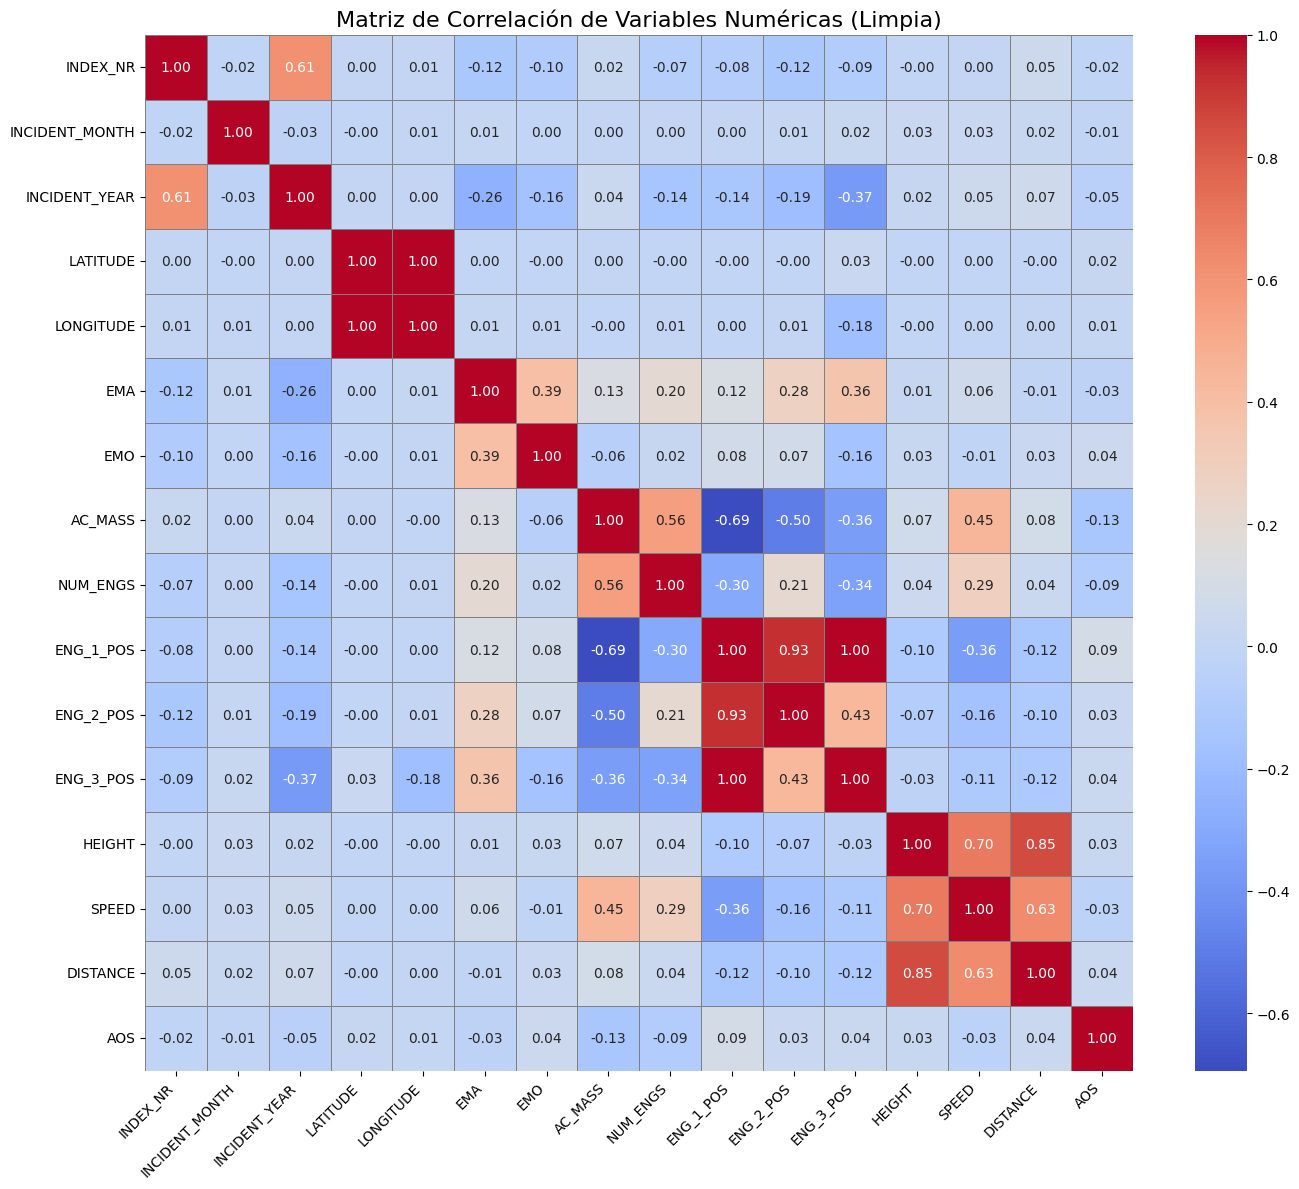

In [ ]:
# Filtrar columnas numéricas con suficiente cantidad de datos no nulos
umbral_minimo = 5000
df_filtrado = df_numericas.loc[:, df_numericas.count() > umbral_minimo]

# Calcular la matriz de correlación solo con columnas válidas
correlation_matrix = df_filtrado.corr()

# Crear el heatmap
plt.figure(figsize=(14, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    linewidths=0.5,
    linecolor='gray',
    mask=correlation_matrix.isnull()
)
plt.title('Matriz de Correlación de Variables Numéricas (Limpia)', fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


Gracias a la visualizacion de la matriz podemos observar lo siguente: primero vemos que las variables HEIGHT, DISTANCE y SPEED tienen una alta correlacion esto debido a que representan caracteristicas del estado de vuelo. Segundo vemos que la variable peso AC_MASS y NUM_ENGS tienen algo de correlacion esto podria deberse a que a mayor peso del avion este requiere mas motores por ultimo LATITUDE y LONGITUDE estan totalmente correlacionadas con un 1.0 aunque estas muestran una correlacion nula con el resto de variables.

In [ ]:
df_numericas.var()

,0
INDEX_NR,6.382942e+10
INCIDENT_MONTH,7.645681e+00
INCIDENT_YEAR,7.110387e+01
LATITUDE,6.687187e+09
LONGITUDE,1.070886e+05
EMA,1.150101e+02
EMO,1.655444e+02
AC_MASS,7.522309e-01
NUM_ENGS,1.765119e-01
ENG_1_POS,4.468177e+00


* INDEX_NR (6.38e+10): Varianza extremadamente alta. Esto es esperable para un índice o identificador único, ya que cada valor es diferente. No tiene valor predictivo intrínseco y es un identificador.

* INCIDENT_MONTH (7.64e+00): Varianza baja. El mes del incidente se distribuye en un rango pequeño (1-12).
* INCIDENT_YEAR (7.11e+01): Varianza moderada. El año de los incidentes abarca un período de varios años.
* LATITUDE (6.68e+09) y LONGITUDE (1.07e+05): Varianzas muy altas. Las coordenadas geográficas pueden variar mucho en un dataset de vuelos globales.
* EMA (1.15e+02) y EMO (1.65e+02): Varianzas bajas a moderadas. Asumiendo que EMA y EMO son Engine Manufacturer y Engine Model respectivamente, esto indica que hay una variedad de fabricantes y modelos de motores en los datos, pero no una cantidad abrumadora de valores únicos si están codificados numéricamente.
* AC_MASS (7.52e-01): Varianza muy baja. Esto podría indicar que la masa de la aeronave está en una escala normalizada o que la mayoría de las aeronaves en el dataset tienen masas similares.
* NUM_ENGS (1.76e-01): Varianza muy baja. Esto sugiere que la mayoría de las aeronaves tienen un número similar de motores (ej. la mayoría son bimotores, con algunas cuatrimotores, etc., sin mucha dispersión).
* ENG_1_POS, ENG_2_POS, ENG_3_POS, ENG_4_POS (4.46e+00 a 2.05e+00): Varianzas bajas. Las posiciones de los motores no varían mucho, lo que tiene sentido ya que están en ubicaciones fijas de la aeronave. La presencia de ENG_4_POS sugiere que hay aeronaves con cuatro motores.
* HEIGHT (3.39e+06), SPEED (2.17e+03), DISTANCE (1.25e+01):
HEIGHT: Varianza muy alta. La altura puede variar drásticamente desde el nivel del suelo hasta altitudes de crucero.
SPEED: Varianza moderada a alta. La velocidad puede variar desde el rodaje hasta la velocidad de crucero.
* DISTANCE: Varianza baja. Esto es interesante. Aunque la distancia puede variar mucho, una varianza tan baja podría indicar que la mayoría de los incidentes ocurren en vuelos de distancias relativamente similares o que DISTANCE podría estar representando algo más específico (ej. distancia al punto de incidente, no necesariamente distancia total del vuelo).
* AOS (4.37e+05): Varianza alta.
* BIRD_BAND_NUMBER (8.29e+15): Varianza extremadamente alta. Si se refiere a un identificador único para aves involucradas en incidentes (bandas de seguimiento), su alta varianza es lógica, similar a INDEX_NR.
* NR_INJURIES (5.71e-01) y NR_FATALITIES (2.73e+00): Varianzas muy bajas. Esto es esperable y positivo, ya que la mayoría de los incidentes no resultan en lesiones o fatalidades, y cuando ocurren, suelen ser números pequeños.

Gracias a esto podemos ver qué tan dispersos están los datos de una variable numérica con respecto a su media. En otras palabras, mide cuánto varían los valores individuales de una columna respecto al valor promedio de esa columna.

## Etapa 3: Preparación de los datos

In [ ]:
df_copia = df.copy()

Creamos una copia del dataset para no perder los valores reales del original y asi siempre contar con un respaldo

#### Tratamiento a los datos nulos

In [ ]:
df_copia = df_copia.drop(['LATITUDE', 'LONGITUDE', 'INDEX_NR','AIRPORT_ID',  'COMMENTS',
                      'PERSON','AMA', 'AMO', 'EMA', 'EMO', 'LUPDATE','INCIDENT_DATE','FAAREGION','TRANSFER','REPORTED_TITLE', 'REPORTED_NAME',], axis=1)
# Lista de columnas a eliminar
cols_to_drop = [
    'FLT', 'NUM_SEEN', 'OTHER_SPECIFY', 'LOCATION',
    'EFFECT', 'ENG_3_POS', 'PRECIPITATION', 'COST_REPAIRS',
    'COST_REPAIRS_INFL_ADJ', 'ENROUTE_STATE', 'COST_OTHER',
    'COST_OTHER_INFL_ADJ', 'ENG_4_POS', 'EFFECT_OTHER',
    'BIRD_BAND_NUMBER'
]
df_copia = df_copia.drop(columns=cols_to_drop)
cols_to_keep = ['PHASE_OF_FLIGHT', 'SIZE', 'AC_CLASS', 'TYPE_ENG', 'SPEED', 'HEIGHT', 'WARNED', 'INDICATED_DAMAGE']
df_copia = df_copia[cols_to_keep]

Eliminamos las siguientes variables:
* LATITUD y LONGITUD : dado que no hacemos análisis predictoro geografico podemos eliminarlas.
* INDEX_NR : Identificador unico, no sirve para predicciones
* TIME: hora del accidente, no usamos tan a detalle la hora
* AIRPORT_ID : Identificador unico, no esta alineado a nuestro obkjetivo
* FLT : identificador del vuelo, no sirve para las predicciones
* COMMENTS : Variable con textot libre y no estructurado.
* cols_to_drop: representan una gran porcentaje de nulos dentro del dataset


Imputacion por la moda

In [ ]:
# Lista de columnas categóricas a imputar
cols_imputar = ['SIZE', 'TYPE_ENG', 'AC_CLASS']

# Imputar cada columna con su moda
for col in cols_imputar:
    moda = df_copia[col].mode()[0]
    df_copia[col].fillna(moda, inplace=True)

# Verificamos que no haya valores nulos en esas columnas
print(df_copia[cols_imputar].isnull().sum())


/tmp/ipython-input-7-3099357607.py:7: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_copia[col].fillna(moda, inplace=True)


SIZE        0
TYPE_ENG    0
AC_CLASS    0
dtype: int64


Durante el análisis del conjunto de datos, identificamos que algunas columnas categóricas presentaban valores nulos. Estas columnas fueron: 'SIZE', 'TYPE_ENG' y 'AC_CLASS'.

Para poder trabajar correctamente con estos datos, fue necesario rellenar esos valores faltantes. Optamos por utilizar la moda de cada columna (es decir, el valor más frecuente) para imputarlos.

imputacion por la media

In [ ]:
# Lista de columnas numéricas a imputar
cols_numericas = ['SPEED', 'HEIGHT']

# Imputar cada columna con su media
for col in cols_numericas:
    media = df_copia[col].mean()
    df_copia[col].fillna(media, inplace=True)

# Verificamos que no haya valores nulos en esas columnas
print(df_copia[cols_numericas].isnull().sum())

SPEED     0
HEIGHT    0
dtype: int64


/tmp/ipython-input-8-3978789502.py:7: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_copia[col].fillna(media, inplace=True)


Al igual que en las variables categóricas, se decidió eliminar los valores nulos, pero esta vez imputando con la media en lugar de la moda, ya que las columnas involucradas ('SPEED' y 'DISTANCE') contienen valores numéricos continuos.



#### tratamiento de outliers

In [ ]:
df_copia = df_copia[df_copia['SPEED'] <= 620]

Limitamos la velocidad de speed dado que investigamos que los avioens se trabaja en el dataset no poseen mas velocidad que eso en MP/H (millas por hora)
* lo vimos en:
[How fast do commercial planes fly?
](https://aviex.goflexair.com/flight-school-training-faq/commercial-plane-speeds)

In [ ]:
from scipy.stats.mstats import winsorize


cols_to_winsorize = ['SPEED', 'HEIGHT']

for col in cols_to_winsorize:
    # Aplicamos winsorize y lo convertimos a una serie para asignarlo de nuevo al DataFrame
    df_copia[col] = pd.Series(winsorize(df_copia[col], limits=[0.05, 0.05]), index=df_copia.index)


df_copia[cols_to_winsorize].describe()

,SPEED,HEIGHT
count,288807.000000,288807.000000
mean,141.850728,741.746796
std,17.166102,732.373549
min,100.000000,0.000000
25%,142.585057,25.000000
50%,142.585057,865.960358
75%,142.585057,865.960358
max,190.000000,3000.000000


### Encoding de las variables

In [ ]:
from sklearn.preprocessing import LabelEncoder

# Convertimos booleano a entero
df_copia.loc[:, "DAMAGE_INDICATOR"] = df_copia["INDICATED_DAMAGE"].astype(int)

# Aplicamos Label Encoding
le = LabelEncoder()
df_copia.loc[:, "AC_CLASS"] = le.fit_transform(df_copia["AC_CLASS"])
df_copia.loc[:, "SIZE"] = le.fit_transform(df_copia["SIZE"])
df_copia.loc[:, "TYPE_ENG"] = le.fit_transform(df_copia["TYPE_ENG"])
df_copia.loc[:, "WARNED"] = le.fit_transform(df_copia["WARNED"])


* Convierte la columna 'INDICATED_DAMAGE' (que es booleana: True / False) a enteros (1 / 0) y la guarda como 'DAMAGE_INDICATOR'.

* al igual que indicated_damage volvemos las categoricas con label encoding para poder hacer que los modelos puedan trabajar con ellas, ya que la mayoría de algoritmos no aceptan directamente variables categóricas en formato de texto. El label encoding transforma estas categorías en valores numéricos, permitiendo que los modelos interpreten y procesen estas variables correctamente.

### Estandarización y Clasificación

### SMOTE

In [ ]:
# Separar características (X) y la variable objetivo (y)
# Eliminamos 'INDICATED_DAMAGE' ya que es la versión original no codificada de 'DAMAGE_INDICATOR'
X = df_copia.drop(['INDICATED_DAMAGE', 'DAMAGE_INDICATOR'], axis=1)
y = df_copia['DAMAGE_INDICATOR']

# Convertir las columnas categóricas codificadas y numéricas a un formato adecuado para SMOTE
# SMOTE trabaja mejor con datos numéricos. Las columnas que ya hemos LabelEncoded
# ('AC_CLASS', 'SIZE', 'TYPE_ENG', 'PHASE_OF_FLIGHT', 'WARNED')
# son tratadas como numéricas por SMOTE.
# Las columnas numéricas ('SPEED', 'HEIGHT', 'NUM_STRUCK') ya están en el formato correcto.

# Convertir 'PHASE_OF_FLIGHT' a numérico (puede usar LabelEncoder o One-Hot if appropriate)
# Si 'PHASE_OF_FLIGHT' aún es categórica en df_copia, codificarla
if df_copia['PHASE_OF_FLIGHT'].dtype == 'object' or df_copia['PHASE_OF_FLIGHT'].dtype == 'category':
    df_copia['PHASE_OF_FLIGHT'] = le.fit_transform(df_copia['PHASE_OF_FLIGHT'])
    # Re-crear X después de codificar 'PHASE_OF_FLIGHT'
    X = df_copia.drop(['INDICATED_DAMAGE', 'DAMAGE_INDICATOR'], axis=1)

# Convertir 'WARNED' a numérico si aún no está hecho (ya convertido a int en el código anterior)
if df_copia['WARNED'].dtype == 'object' or df_copia['WARNED'].dtype == 'category':
     df_copia['WARNED'] = df_copia['WARNED'].astype(int)
     # Re-crear X después de codificar 'WARNED'
     X = df_copia.drop(['INDICATED_DAMAGE', 'DAMAGE_INDICATOR'], axis=1)


# Aplicar SMOTE para sobremuestrear la clase minoritaria ('INDICATED_DAMAGE' == 1)
smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X, y)

# Opcional: Ver la distribución de clases después de SMOTE
print("Distribución de clases en la variable objetivo después de SMOTE:")
print(y_res.value_counts())

# Ahora puedes usar X_res y y_res para entrenar tu modelo
# Por ejemplo, puedes dividirlos en conjuntos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X_res, y_res, test_size=0.2, random_state=42, stratify=y_res)


Distribución de clases en la variable objetivo después de SMOTE:
DAMAGE_INDICATOR
0    269065
1    269065
Name: count, dtype: int64


Aplicamos SMOTE porque la variable objetivo presenta un fuerte desbalance entre clases. Este desbalance puede causar que los modelos de clasificación generen predicciones sesgadas hacia la clase mayoritaria, disminuyendo la capacidad de generalización y afectando negativamente métricas como el recall o la F1-score para la clase minoritaria. Al balancear las clases mediante la generación sintética de ejemplos de la clase minoritaria, buscamos mejorar la capacidad del modelo para aprender patrones relevantes de ambas clases y así obtener mejores resultados predictivos.

In [ ]:
# Concatenar X_res y y_res para ver la distribución de 'INDICATED_DAMAGE' en el DataFrame resultante
df_resampled = pd.concat([X_res, y_res.rename('INDICATED_DAMAGE')], axis=1)

# Contar los valores únicos en la columna 'INDICATED_DAMAGE' después de SMOTE
damage_counts_smote = df_resampled['INDICATED_DAMAGE'].value_counts().reset_index()
damage_counts_smote.columns = ['INDICATED_DAMAGE', 'COUNT']

# Crear el gráfico de pastel
fig = px.pie(damage_counts_smote, values='COUNT', names='INDICATED_DAMAGE', title='Distribución de Daños Indicados después de SMOTE')
fig.show()

# Etapa 4: Modelamiento

## Modelos de Clasificación


### Support Vector Machine


Support Vector Machine (SVM) Classifier Performance:

Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.72      0.65      5405
           1       0.65      0.52      0.58      5358

    accuracy                           0.62     10763
   macro avg       0.62      0.62      0.62     10763
weighted avg       0.62      0.62      0.62     10763



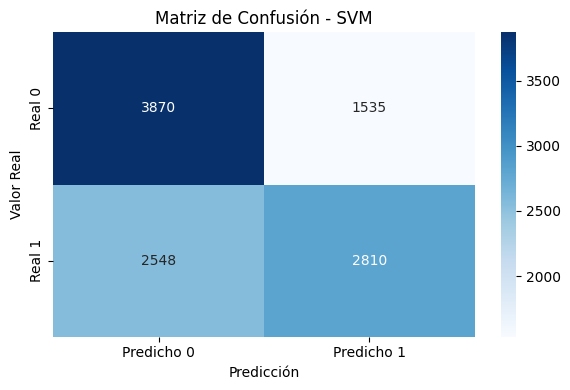

In [ ]:
X_sample, _, y_sample, _ = train_test_split(X_res, y_res, train_size=0.1, stratify=y_res, random_state=42)


X_train, X_test, y_train, y_test = train_test_split(X_sample, y_sample, test_size=0.2, random_state=42)


svm_model = SVC(random_state=42)
svm_model.fit(X_train, y_train)


y_pred_svm = svm_model.predict(X_test)


print("\nSupport Vector Machine (SVM) Classifier Performance:")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))


cm = confusion_matrix(y_test, y_pred_svm)


plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicho 0", "Predicho 1"],
            yticklabels=["Real 0", "Real 1"])
plt.xlabel("Predicción")
plt.ylabel("Valor Real")
plt.title("Matriz de Confusión - SVM")
plt.tight_layout()
plt.show()

Gracias a las metricas vemos que el modelo tiene un recall de la clase 0 es de 76% lo que dice que tiende a predecir que no hay daño cuando realmente no hay por otro lado vemos que el recall de la clase 1 es de 52% por lo que el modelo se equivoca en casi la mitad de los caso donde si hay daño.

### Random Forest


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix


model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)



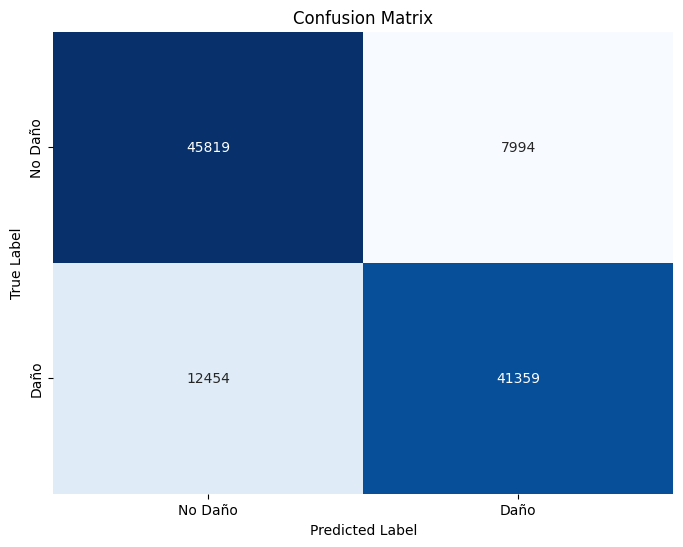


Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.85      0.82     53813
           1       0.84      0.77      0.80     53813

    accuracy                           0.81    107626
   macro avg       0.81      0.81      0.81    107626
weighted avg       0.81      0.81      0.81    107626



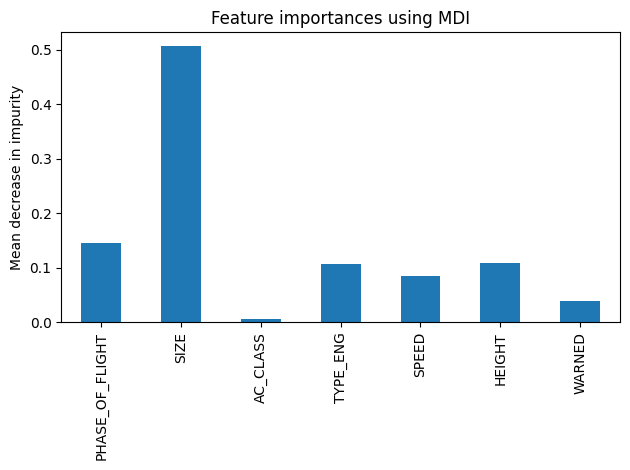

In [ ]:
# Evaluate the model
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['No Daño', 'Daño'], yticklabels=['No Daño', 'Daño'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Optional: Get feature importances
importances = model.feature_importances_
feature_names = X_train.columns
forest_importances = pd.Series(importances, index=feature_names)

fig, ax = plt.subplots()
forest_importances.plot.bar()
ax.set_title("Feature importances using MDI")
ax.set_ylabel("Mean decrease in impurity")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import cross_val_score
cv_scores = cross_val_score(model, X_res, y_res, cv=5, scoring='accuracy')

print(f"Cross-validation Accuracy Scores: {cv_scores}")
print(f"Mean CV Accuracy: {cv_scores.mean():.4f}")
print(f"Standard Deviation of CV Accuracy: {cv_scores.std():.4f}")

cv_f1_scores = cross_val_score(model, X_res, y_res, cv=5, scoring='f1')
print(f"\nCross-validation F1-Scores: {cv_f1_scores}")
print(f"Mean CV F1-Score: {cv_f1_scores.mean():.4f}")
print(f"Standard Deviation of CV F1-Score: {cv_f1_scores.std():.4f}")


Cross-validation Accuracy Scores: [0.65570587 0.81064055 0.84107    0.83898872 0.83404568]
Mean CV Accuracy: 0.7961
Standard Deviation of CV Accuracy: 0.0710

Cross-validation F1-Scores: [0.69860997 0.80497234 0.82955848 0.8285327  0.82415949]
Mean CV F1-Score: 0.7972
Standard Deviation of CV F1-Score: 0.0501


Classification Report for Training Data:
              precision    recall  f1-score   support

           0       0.80      0.86      0.83    215252
           1       0.85      0.78      0.81    215252

    accuracy                           0.82    430504
   macro avg       0.82      0.82      0.82    430504
weighted avg       0.82      0.82      0.82    430504



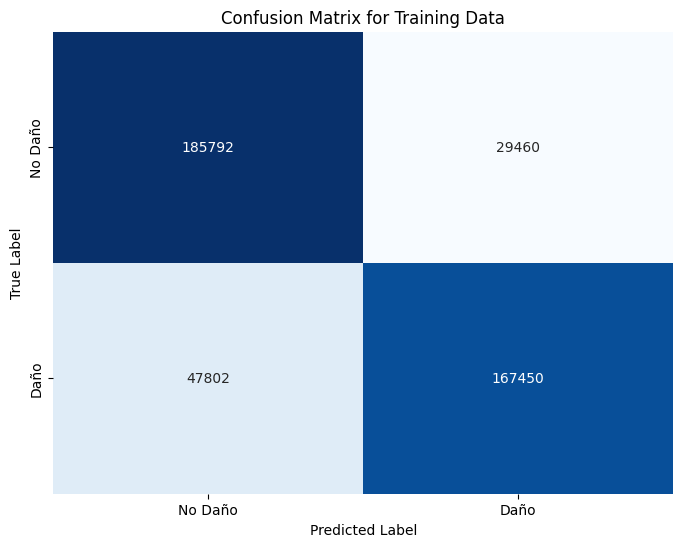

In [ ]:
y_train_pred = model.predict(X_train)

# Print classification report for the training set
print("Classification Report for Training Data:")
print(classification_report(y_train, y_train_pred))

# Compute and plot confusion matrix for the training set
cm_train = confusion_matrix(y_train, y_train_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_train, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['No Daño', 'Daño'], yticklabels=['No Daño', 'Daño'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for Training Data')
plt.show()

En este proyecto, el objetivo fue predecir si un impacto causó daño al avión (INDICATED_DAMAGE). La accuracy indica el porcentaje total de aciertos del modelo; el 81% implica que se predijo correctamente la presencia o ausencia de daño en los casos.
La precisión mide cuántos de los casos predichos como "con daño" realmente lo eran. En este contexto, una precisión alta evita generar reportes falos.
El F1-score resume precisión y recall en un solo valor equilibrado. Finalmente, la validación cruzada demostró que el modelo es estable y generalizan bien, con desviaciones estándar bajas.

El True Positive ocurre cuando el modelo predice daño y efectivamente lo hubo el daño o el no daño, lo cual es nuestro objetivo en este contexto dado que permite mtomar decisioones critcas.

### Gradient Boosting

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix

gb_model = GradientBoostingClassifier(random_state=42)
gb_model.fit(X_train, y_train)
y_pred_gb = gb_model.predict(X_test)



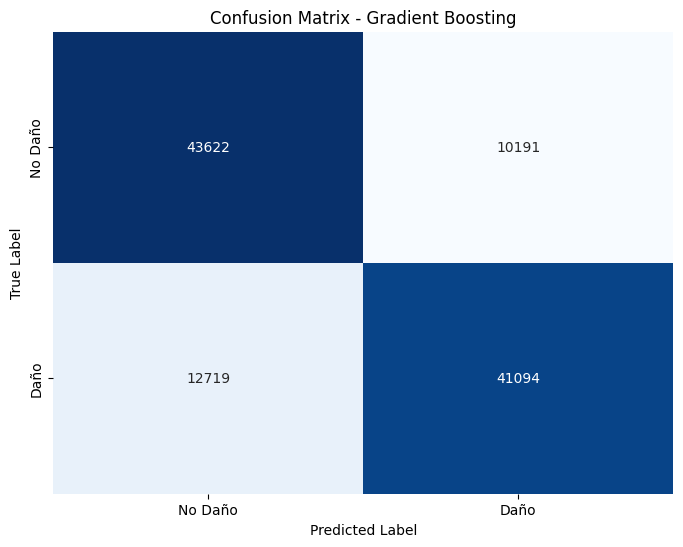


Classification Report (Gradient Boosting):
              precision    recall  f1-score   support

           0       0.77      0.81      0.79     53813
           1       0.80      0.76      0.78     53813

    accuracy                           0.79    107626
   macro avg       0.79      0.79      0.79    107626
weighted avg       0.79      0.79      0.79    107626



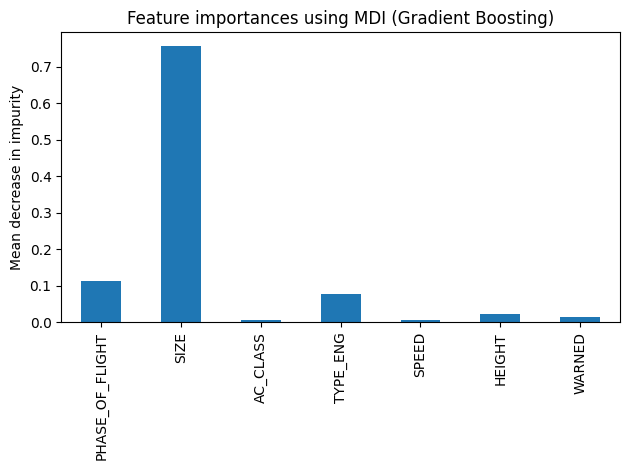

In [ ]:
cm_gb = confusion_matrix(y_test, y_pred_gb)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_gb, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['No Daño', 'Daño'], yticklabels=['No Daño', 'Daño'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Gradient Boosting')
plt.show()
print("\nClassification Report (Gradient Boosting):")
print(classification_report(y_test, y_pred_gb))


importances_gb = gb_model.feature_importances_
feature_names_gb = X_train.columns
gb_importances = pd.Series(importances_gb, index=feature_names_gb)

fig, ax = plt.subplots()
gb_importances.plot.bar()
ax.set_title("Feature importances using MDI (Gradient Boosting)")
ax.set_ylabel("Mean decrease in impurity")
plt.tight_layout()
plt.show()

In [ ]:
cv_scores_gb = cross_val_score(gb_model, X_res, y_res, cv=5, scoring='accuracy')

print(f"Gradient Boosting Cross-validation Accuracy Scores: {cv_scores_gb}")
print(f"Mean GB CV Accuracy: {cv_scores_gb.mean():.4f}")
print(f"Standard Deviation of GB CV Accuracy: {cv_scores_gb.std():.4f}")

cv_f1_scores_gb = cross_val_score(gb_model, X_res, y_res, cv=5, scoring='f1')
print(f"\nGradient Boosting Cross-validation F1-Scores: {cv_f1_scores_gb}")
print(f"Mean GB CV F1-Score: {cv_f1_scores_gb.mean():.4f}")
print(f"Standard Deviation of GB CV F1-Score: {cv_f1_scores_gb.std():.4f}")


Gradient Boosting Cross-validation Accuracy Scores: [0.62527642 0.78218089 0.82741159 0.82169736 0.81773921]
Mean GB CV Accuracy: 0.7749
Standard Deviation of GB CV Accuracy: 0.0764

Gradient Boosting Cross-validation F1-Scores: [0.68072137 0.77826856 0.81516126 0.81043544 0.80655214]
Mean GB CV F1-Score: 0.7782
Standard Deviation of GB CV F1-Score: 0.0504


Classification Report for Training Data (Gradient Boosting):
              precision    recall  f1-score   support

           0       0.78      0.81      0.79    215252
           1       0.80      0.77      0.78    215252

    accuracy                           0.79    430504
   macro avg       0.79      0.79      0.79    430504
weighted avg       0.79      0.79      0.79    430504



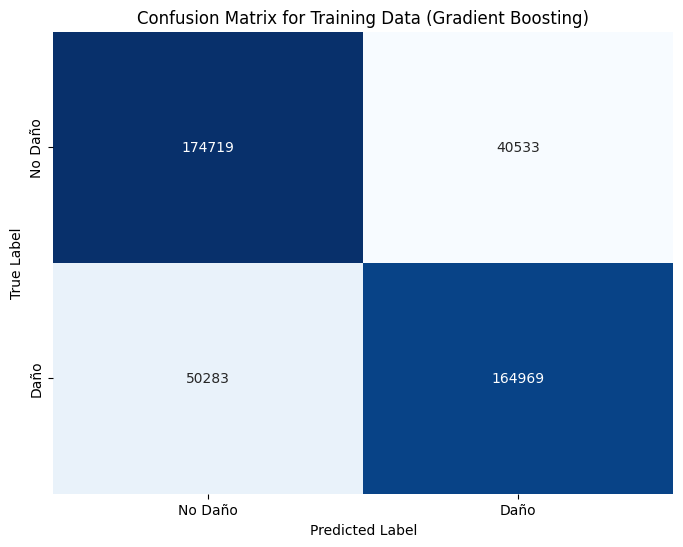

In [ ]:
# Make predictions on the training set for Gradient Boosting
y_train_pred_gb = gb_model.predict(X_train)

# Print classification report for the training set (Gradient Boosting)
print("Classification Report for Training Data (Gradient Boosting):")
print(classification_report(y_train, y_train_pred_gb))

# Compute and plot confusion matrix for the training set (Gradient Boosting)
cm_train_gb = confusion_matrix(y_train, y_train_pred_gb)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_train_gb, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['No Daño', 'Daño'], yticklabels=['No Daño', 'Daño'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for Training Data (Gradient Boosting)')
plt.show()

El modelo Gradient Boosting alcanzó una accuracy del 79%, lo que indica que predijo correctamente 79 de cada 100 reportes.  
Además, la validación cruzada mostró una accuracy media de 77.5% y F1 promedio de 77.8%, con baja desviación estándar, lo que confirma que el modelo es estable y generaliza bien.
en nuestro contetxto el true postive muestrea bien lo que representan los casos donde el modelo predijo daño y realmente lo hubo estos son aciertos críticos. que es nuestro ideal para poder usarlos en el contexto de la FAA



## Modelos De regresión


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.tree import DecisionTreeRegressor

### Regresion lineal multiple

In [ ]:
features = ['HEIGHT', 'SPEED', 'AC_MASS', 'NUM_ENGS']
target = 'DISTANCE'
df_reg = df[[target] + features].dropna(subset=[target]).copy()
df_reg[features] = df_reg[features].fillna(df_reg[features].mean())
X = df_reg[features]
y = df_reg[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Entrenar modelo
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

#R²a
n = X_test.shape[0]
p = X_test.shape[1]
r2_adj = 1 - (1 - r2) * (n - 1) / (n - p - 1)

print("Metricas de Regresión Lineal multiple para predecir DISTANCE:")
print(f"MAE:  {mae:.2f}")
print(f"MSE:  {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R2 ajustado: {r2_adj:.4f}")

Metricas de Regresión Lineal multiple para predecir DISTANCE:
MAE:  0.99
MSE:  4.47
RMSE: 2.11
R2 ajustado: 0.6410


Insigh: Usted se preguntara ¿Porque distancia?, debido a que identificar la fase de vuelo por distancia, podriamos saber en que parte del trayecto  hay mas accidentes con la fauna, asi tomando medidas el cual puedan minimzar el daño tanto a las aeronaves como a los animales.

### arbol de desicion

In [ ]:
model_dt = DecisionTreeRegressor(random_state=42)
model_dt.fit(X_train, y_train)
y_pred_dt = model_dt.predict(X_test)

mse_dt = mean_squared_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mse_dt)
mae_dt = mean_absolute_error(y_test, y_pred_dt)
r2_dt = r2_score(y_test, y_pred_dt)

# R² ajustado
n = X_test.shape[0]
p = X_test.shape[1]
r2_adj_dt = 1 - (1 - r2_dt) * (n - 1) / (n - p - 1)

# Resultados
print("\nRegresión con arbol de Decisión:")
print(f"MAE:  {mae_dt:.2f}")
print(f"MSE:  {mse_dt:.2f}")
print(f"RMSE: {rmse_dt:.2f}")
print(f"R2 ajustado: {r2_adj_dt:.4f}")


Regresión con arbol de Decisión:
MAE:  0.44
MSE:  4.59
RMSE: 2.14
R2 ajustado: 0.6319


## Modelos No Supervisados

## kmeans

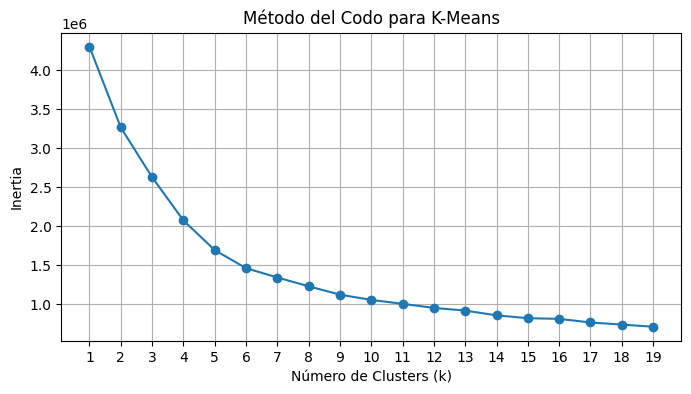

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_res)
X_kmeans = X_scaled
inertia = []
# Probar con diferentes números de clusters
k_range = range(1, 20)
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_kmeans)
    inertia.append(kmeans.inertia_)

# Graficar el método del codo
plt.figure(figsize=(8, 4))
plt.plot(k_range, inertia, marker='o')
plt.title('Método del Codo para K-Means')
plt.xlabel('Número de Clusters (k)')
plt.ylabel('Inertia')
plt.xticks(k_range)
plt.grid(True)
plt.show()

El punto k=5 aparece como un posible codo, ya que después la curva comienza a suavizarse.

Para K=2, Silhouette Score (muestra): 0.3160
Para K=3, Silhouette Score (muestra): 0.3417
Para K=4, Silhouette Score (muestra): 0.3597
Para K=5, Silhouette Score (muestra): 0.3813
Para K=6, Silhouette Score (muestra): 0.3644
Para K=7, Silhouette Score (muestra): 0.3679
Para K=8, Silhouette Score (muestra): 0.3670
Para K=9, Silhouette Score (muestra): 0.3673
Para K=10, Silhouette Score (muestra): 0.3921
Para K=11, Silhouette Score (muestra): 0.3932
Para K=12, Silhouette Score (muestra): 0.4025
Para K=13, Silhouette Score (muestra): 0.3919
Para K=14, Silhouette Score (muestra): 0.4167
Para K=15, Silhouette Score (muestra): 0.4275
Para K=16, Silhouette Score (muestra): 0.4236
Para K=17, Silhouette Score (muestra): 0.4277
Para K=18, Silhouette Score (muestra): 0.4319
Para K=19, Silhouette Score (muestra): 0.4352


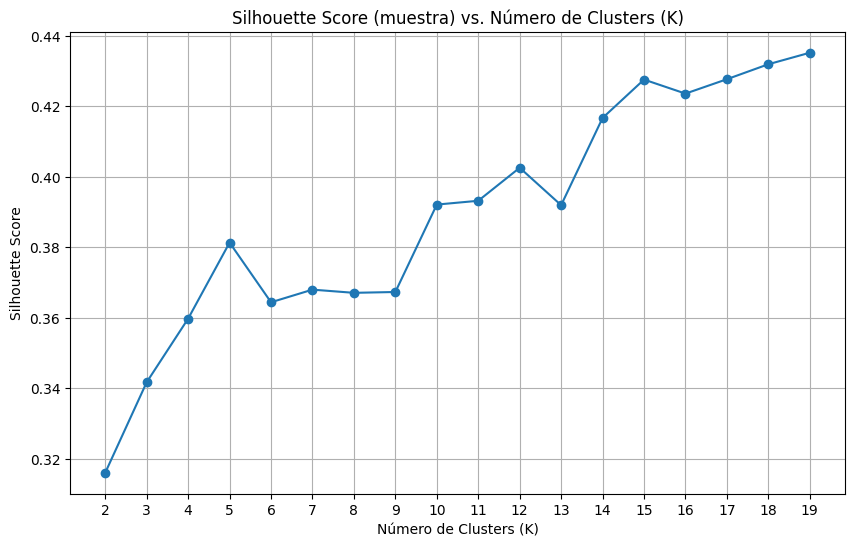

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import numpy as np
import matplotlib.pyplot as plt

# Parámetros
random_state = 42
sample_size = 10000  # Tamaño de muestra para evaluación
k_range = range(2, 20)
silhouette_scores = []

# Crear muestra aleatoria de X_scaled
np.random.seed(random_state)
indices = np.random.choice(len(X_scaled), size=sample_size, replace=False)
X_sample = X_scaled[indices]  # Subconjunto para evaluación

# Loop sobre los valores de k
for k in k_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=random_state)
    cluster_labels = kmeans.fit_predict(X_scaled)  # Entrenamiento sobre todo X_scaled
    # Calcular silueta sobre la muestra
    score = silhouette_score(X_sample, cluster_labels[indices])  # Solo las etiquetas correspondientes
    silhouette_scores.append(score)
    print(f"Para K={k}, Silhouette Score (muestra): {score:.4f}")

# Graficar resultados
plt.figure(figsize=(10, 6))
plt.plot(k_range, silhouette_scores, marker='o')
plt.title('Silhouette Score (muestra) vs. Número de Clusters (K)')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(k_range)
plt.grid(True)
plt.show()


El valor K=5 representa un buen equilibrio ya que alcanza un puntaje razonablemente alto y se encuentra antes de que la curva comience a estabilizarse.

In [ ]:
from sklearn.metrics import davies_bouldin_score

dbi_scores = []
k_range_dbi = range(2, 20)

for k in k_range_dbi:
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    dbi = davies_bouldin_score(X_scaled, labels)
    dbi_scores.append(dbi)
    print(f"K={k}, Davies-Bouldin Index: {dbi:.4f}")


K=2, Davies-Bouldin Index: 1.4934
K=3, Davies-Bouldin Index: 1.1405
K=4, Davies-Bouldin Index: 1.0163
K=5, Davies-Bouldin Index: 1.0220
K=6, Davies-Bouldin Index: 1.0946
K=7, Davies-Bouldin Index: 1.0099
K=8, Davies-Bouldin Index: 1.0706
K=9, Davies-Bouldin Index: 1.0745
K=10, Davies-Bouldin Index: 1.0571
K=11, Davies-Bouldin Index: 1.0280
K=12, Davies-Bouldin Index: 1.0492
K=13, Davies-Bouldin Index: 1.1328
K=14, Davies-Bouldin Index: 1.1470
K=15, Davies-Bouldin Index: 1.1709
K=16, Davies-Bouldin Index: 1.1362
K=17, Davies-Bouldin Index: 1.1652
K=18, Davies-Bouldin Index: 1.1652
K=19, Davies-Bouldin Index: 1.1579


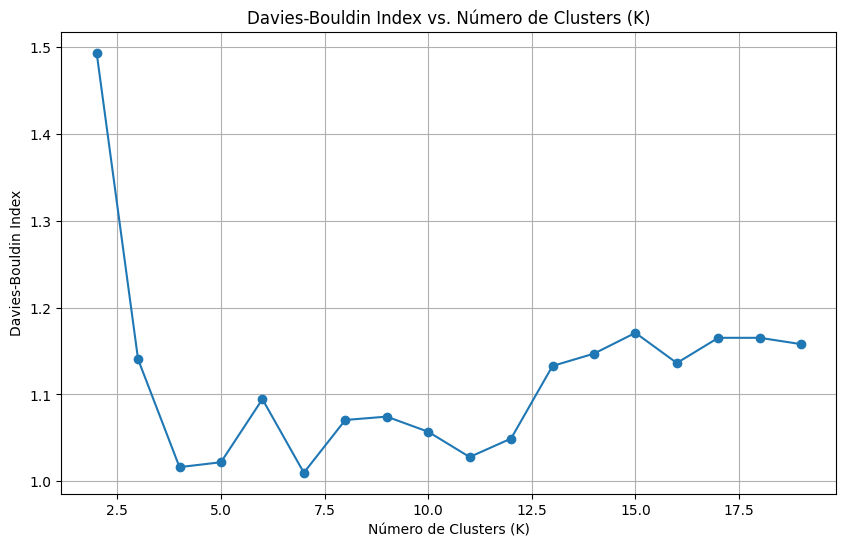

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(k_range_dbi, dbi_scores, marker='o', linestyle='-')
plt.title('Davies-Bouldin Index vs. Número de Clusters (K)')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('Davies-Bouldin Index')
plt.grid(True)
plt.show()


El valor mínimo del DBI se alcanza en K=7 (1.0099), lo que sugiere que 7 clusters proporcionan el mejor equilibrio entre cohesión y separación desde la perspectiva de esta métrica, sin embargo, K=4 y K=5 también ofrecen valores competitivos y estables, siendo opciones válidas si se prioriza la interpretabilidad y simplicidad.

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_res)

# Volver a hacer clustering con KMeans
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

# Ahora sí puedes agregar los clusters
X_res['Cluster'] = clusters

In [ ]:
cluster_summary = X_res.groupby('Cluster').mean(numeric_only=True)
print(cluster_summary)



         PHASE_OF_FLIGHT       SPEED       HEIGHT    WARNED
Cluster                                                    
0               1.242240  140.482980   528.845299  0.863655
1               9.823860  138.805580   543.983241  1.023258
2               1.191597  176.986913  2568.340072  0.618939
3               4.435494  121.937531  1070.526325  0.470364
4               3.438490  118.670728   651.214849  0.593200


Cluster 0:
Corresponde a fases iniciales del vuelo,
La velocidad es alta, aunque no la máxima.
La altura es baja comparada con otros clusters.
Las aeronaves presentan un nivel de alerta elevado, probablemente debido a maniobras tempranas con velocidad considerable a baja altura.

Cluster 1:
Corresponde a fases avanzadas del vuelo.
La velocidad es moderada.
La altura es la más alta entre los clusters con fase alta, posiblemente crucero o aproximación final.
Las aeronaves muestran el nivel de alerta más alto, indicando mayor complejidad o riesgo en esta etapa.

Cluster 2:
Corresponde a fases iniciales o temprano ascenso.
Presenta la velocidad más alta entre todos los clusters.
La altura es la más elevada, indicando vuelos en ascenso o crucero temprano.
El nivel de alerta es bajo, lo que sugiere condiciones estables y menor riesgo.

Cluster 3:
Corresponde a fases intermedias o medias-altas del vuelo.
La velocidad es la más baja entre todos los clusters.
La altura es media.
El nivel de alerta es el más bajo, reflejando menor incidencia de advertencias.

Cluster 4:
Corresponde a una fase intermedia o transición.
La velocidad es la más baja entre los clusters.
La altura es baja.
El nivel de alerta es moderado, posiblemente por maniobras cercanas al suelo.

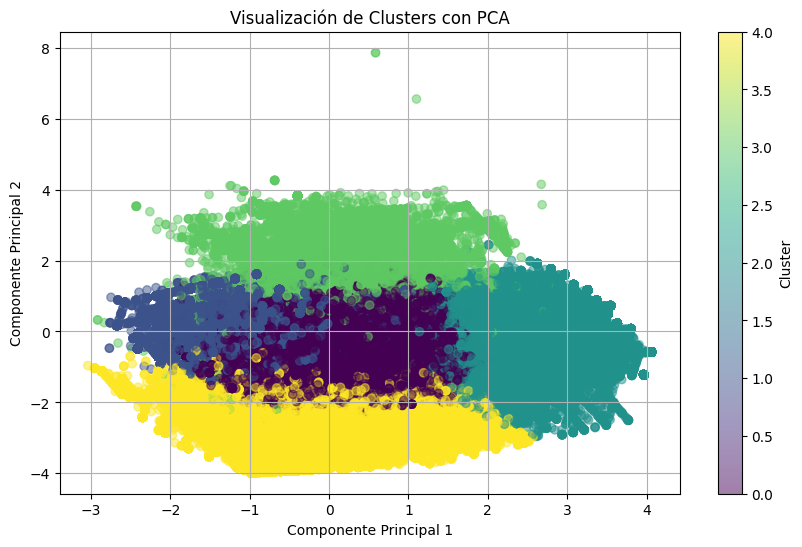

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Aplicar PCA a los datos escalados
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Crear scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=X_res['Cluster'], cmap='viridis', alpha=0.5)
plt.title('Visualización de Clusters con PCA')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.colorbar(label='Cluster')
plt.grid(True)
plt.show()


Los niveles de alerta no dependen solo de la velocidad o altura, sino de la fase del vuelo. Por ejemplo, el cluster 1  tiene el nivel de alerta más alto, probablemente por la complejidad en aproximación o crucero final. En cambio, el cluster 2, que tiene la velocidad más alta y gran altura, muestra bajo nivel de alerta porque el vuelo está estable. El cluster 0 también es fase inicial, pero con alerta alta, quizás por maniobras críticas al despegar. El cluster 3, con velocidad y alerta bajas, indica fases más estables. Y el cluster 4, aunque con velocidad baja, tiene alerta moderada, seguro por maniobras cerca del suelo. Esto ayuda a identificar en qué fases hay más riesgo y dónde enfocar la atención.